# M029, session 25 (2026-09-04) — trials 19-24

Trials 19-24 span two blocks:
- **block 2**: trials 14-20 (so trials 19, 20 fall here)
- **block 3**: trials 21-27 (so trials 21, 22, 23, 24 fall here)

Section 1 gives the full 6-panel figure for each block (target LUT, performance,
force distribution, force trajectories, lickport, force-vs-time), restricted to the
trials of interest. Section 2 gives two focused comparison plots across just these
two blocks: time-to-reward per trial (color-coded by block) and the
Posterior-Anterior(g) force distribution/trajectories, both restricted to trials 19-24.

In [1]:
from pathlib import Path
import sys

repo_root = next((parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (parent / 'ndnf_pipeline').exists()), None)
if repo_root is None:
    raise RuntimeError('Could not locate the repository root')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import datajoint as dj
dj.config.load(str(repo_root / 'dj_local_conf.json'))
dj.conn()

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from ndnf_pipeline import experiment
from ndnf_pipeline.plot import behavior_plots as bp
from ndnf_pipeline.plot.behavior_plots import plot_block_force_figure

subject_id = 'M029'
session = 25
trials_by_block = {2: [19, 20], 3: [21, 22, 23, 24]}
block_colors = {2: 'tab:blue', 3: 'tab:red'}
uniform_force_range = np.array([-1, 1, -1, 1]) * 15  # g

C:\NDNF-pipeline\.venv\Lib\site-packages\datajoint\plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # requires setuptools<82


[2026-09-23 10:48:34,385][INFO]: DataJoint is configured from C:\NDNF-pipeline\dj_local_conf.json


[2026-09-23 10:48:34,469][INFO]: DataJoint 0.14.9 connected to rozmar@datajoint.ndnf.koki.hun-ren.hu:3306


## 1. Full block figures

### Block 2 (trials 19-20)

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


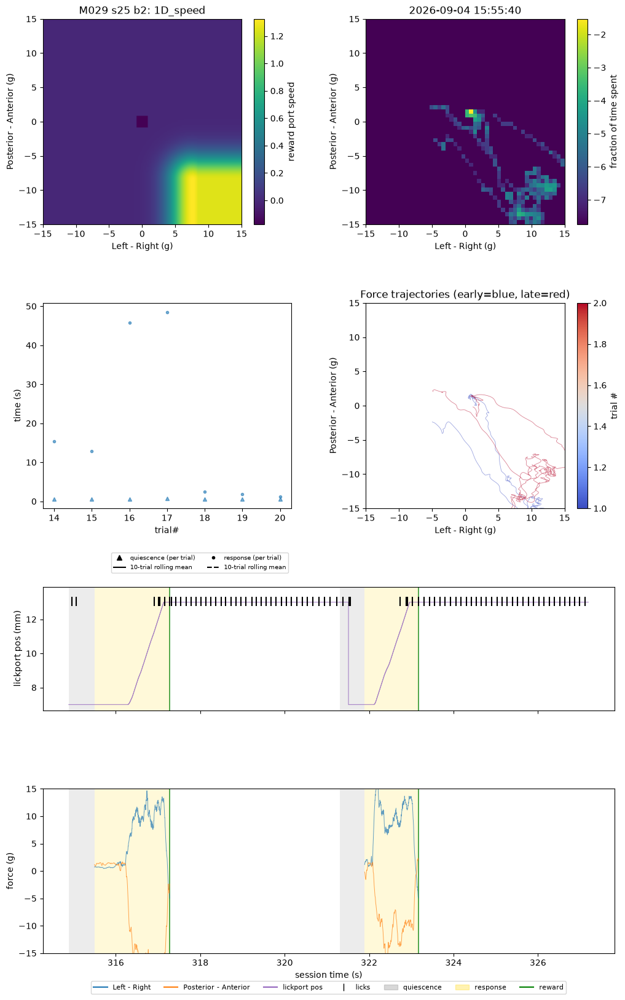

In [3]:
fig_b2 = plot_block_force_figure(subject_id, session, block=2, trials=trials_by_block[2],
                                  filter_method='gaussian', filter_sigma_ms=3.0,
                                  epochs=['response'],
                                  uniform_force_range=uniform_force_range)
plt.show()


### Block 3 (trials 21-24)

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


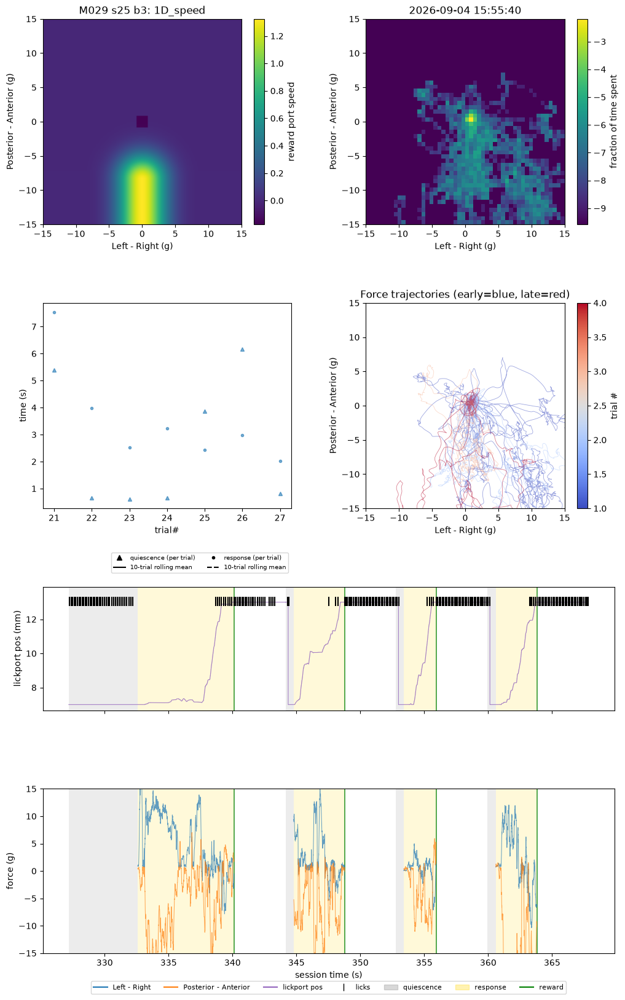

In [4]:
fig_b3 = plot_block_force_figure(subject_id, session, block=3, trials=trials_by_block[3],
                                  filter_method='gaussian', filter_sigma_ms=3.0,
                                  epochs=['response'],
                                  uniform_force_range=uniform_force_range)
plt.show()


## 2. Focused comparison across the two blocks (trials 19-24 only)

### Time to reward x block

Saved to

C:\NDNF-pipeline\Notebooks\figures\M029_s25_time_to_reward_trials_18_27.png

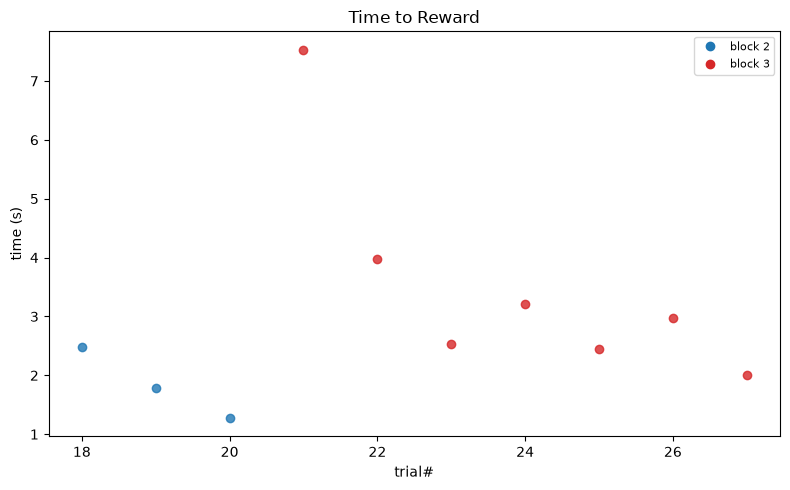

In [5]:
trials_by_block_18_27 = {2: [18, 19, 20], 3: [21, 22, 23, 24, 25, 26, 27]}

fig, ax = plt.subplots(figsize=(8, 5))

for block, trials in trials_by_block_18_27.items():
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    all_trials, quiescence_value, response_value = bp._fetch_quiescence_response(experiment, key)
    mask = np.isin(all_trials, trials)
    ax.plot(all_trials[mask], response_value[mask], '.', color=block_colors[block], markersize=12, alpha=0.8)

handles = [
    Line2D([0], [0], color=block_colors[2], marker='o', linestyle='None', label='block 2'),
    Line2D([0], [0], color=block_colors[3], marker='o', linestyle='None', label='block 3'),
]
ax.legend(handles=handles, loc='best', fontsize=8)
ax.set_title('Time to Reward')
ax.set_xlabel('trial#')
ax.set_ylabel('time (s)')
plt.tight_layout()

out_path = repo_root / 'Notebooks' / 'figures' / f'{subject_id}_s{session}_time_to_reward_trials_18_27.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

### Posterior-Anterior (g): force distribution and trajectories

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


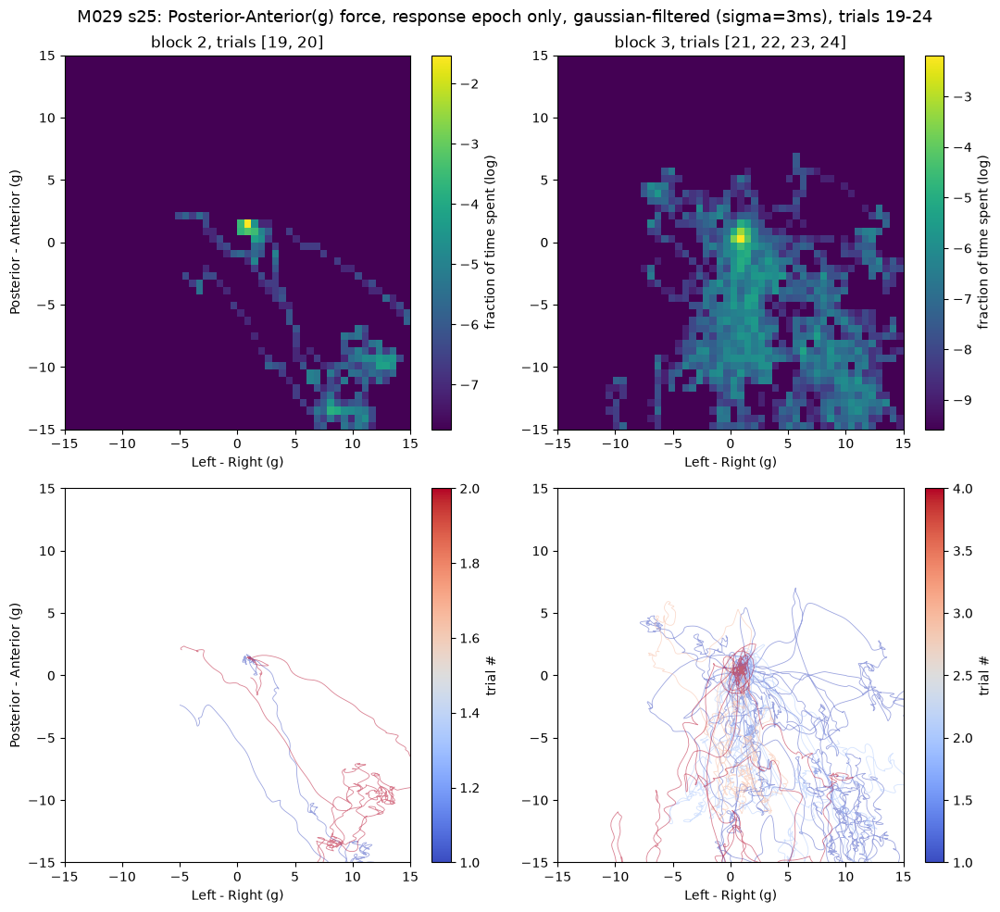

In [6]:
def lr_pa_traces_for_trials(subject_id, session, block, trials, filter_sigma_ms=3.0, epochs=('response',)):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
    _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

    trial_restriction = [{'trial': int(t)} for t in trials]
    f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0} & trial_restriction)
    f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                & {**key, 'force_axis_idx': 1} & trial_restriction)
    force_trials, force_trace_times, f0_ = f0_query.fetch('trial', 'force_trace_time', 'force_trace_value', order_by='trial')
    f1_ = f1_query.fetch('force_trace_value', order_by='trial')
    f0_baseline = np.median(np.concatenate(f0_))
    f1_baseline = np.median(np.concatenate(f1_))
    f0 = [f - f0_baseline for f in f0_]
    f1 = [f - f1_baseline for f in f1_]
    lr_traces, pa_traces = bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)

    # gaussian-smooth each trial's trace (sigma given in ms, converted to samples using
    # this block's own force trace sample interval), then restrict to the requested epoch(s)
    sample_interval_s = bp._estimate_sample_interval(force_trace_times)
    filter_sigma = bp.ms_to_samples_float(filter_sigma_ms, sample_interval_s, minimum=1e-6)
    lr_traces, pa_traces = bp._filter_traces(lr_traces, pa_traces, 'gaussian', sigma=filter_sigma)

    epoch_windows = bp._fetch_epoch_windows(experiment, key)
    lr_traces, pa_traces = bp._filter_traces_by_epochs(force_trials, force_trace_times, lr_traces, pa_traces,
                                                        epoch_windows, epochs)
    return lr_traces, pa_traces


uniform_range = uniform_force_range
histrange = [uniform_range[:2], uniform_range[2:]]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for col, (block, trials) in enumerate(trials_by_block.items()):
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)

    ax_hist = axes[0, col]
    forcehist, binx, biny = bp._force_histogram(lr_traces, pa_traces, histrange)
    im = ax_hist.imshow(forcehist.T, origin='lower', extent=[binx[0], binx[-1], biny[0], biny[-1]], aspect='auto')
    ax_hist.set_xlabel('Left - Right (g)')
    if col == 0:
        ax_hist.set_ylabel('Posterior - Anterior (g)')
    ax_hist.set_title(f'block {block}, trials {trials}')
    fig.colorbar(im, ax=ax_hist, label='fraction of time spent (log)')

    ax_traj = axes[1, col]
    bp._plot_force_trajectories(ax_traj, lr_traces, pa_traces, uniform_force_range=uniform_range, title=None, ylabel=(col == 0))

fig.suptitle(f'{subject_id} s{session}: Posterior-Anterior(g) force, response epoch only, gaussian-filtered (sigma=3ms), trials 19-24', fontsize=13)
plt.tight_layout()
plt.show()


## Poster figure: Time to reward, log scale, blocks 1 / 2 / 3

Three panels side by side (no dividing spine between them), one per block group
(block 1 = raw blocks 0+1, trials 0-13; block 2 = trials 14-20; block 3 = trials
21-27), sharing one y axis. Y axis is log-scaled. Only the response duration
('time to reward', go event -> threshold crossing) is plotted - no quiescence
markers, no rolling-mean lines. Saved as a single PNG for the poster.

Saved to

C:\NDNF-pipeline\Notebooks\figures\M029_s25_time_to_reward_blocks_01_2_3_log.png

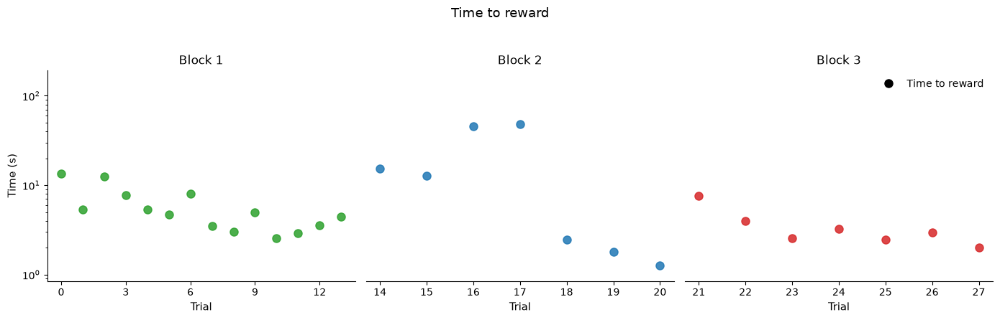

In [7]:
block_groups = [
    ('Block 1', [0, 1]),
    ('Block 2', [2]),
    ('Block 3', [3]),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
block_colors_3 = ['tab:green', 'tab:blue', 'tab:red']

group_data = []
for label, blocks in block_groups:
    trials_parts, response_parts = [], []
    for block in blocks:
        key = {'subject_id': subject_id, 'session': session, 'block': block}
        t, _, r = bp._fetch_quiescence_response(experiment, key)
        trials_parts.append(t)
        response_parts.append(r)
    trials = np.concatenate(trials_parts)
    response_value = np.concatenate(response_parts)
    order = np.argsort(trials)
    group_data.append((label, trials[order], response_value[order]))

all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()

for i, (ax, (label, trials, response_value)) in enumerate(zip(axes, group_data)):
    ax.plot(trials, response_value, 'o', color=block_colors_3[i], markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(label, fontsize=12)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)  # headroom at top, clear of data, for the legend
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)
    if i > 0:
        # no dividing wall between panels: drop the left spine/ticks except on the
        # first panel, which carries the (shared) y axis for all three
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False, which='both')

axes[0].set_ylabel('Time (s)', fontsize=11)

response_handle = Line2D([0], [0], marker='o', linestyle='None', color='black',
                          markersize=8, label='Time to reward')
axes[-1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)

fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])

fig_dir = repo_root / 'Notebooks' / 'figures'
fig_dir.mkdir(exist_ok=True)
out_path = fig_dir / f'{subject_id}_s{session}_time_to_reward_blocks_01_2_3_log.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Alternative versions, for comparison

Every design tried for the 'time to reward' poster figure, saved separately so
they can be compared side by side and one picked as the final version.

In [8]:
def fetch_group_data(block_groups):
    group_data = []
    for label, blocks in block_groups:
        trials_parts, response_parts = [], []
        for block in blocks:
            key = {'subject_id': subject_id, 'session': session, 'block': block}
            t, _, r = bp._fetch_quiescence_response(experiment, key)
            trials_parts.append(t)
            response_parts.append(r)
        trials = np.concatenate(trials_parts)
        response_value = np.concatenate(response_parts)
        order = np.argsort(trials)
        group_data.append((label, trials[order], response_value[order]))
    return group_data

block_groups_3 = [('Block 1', [0, 1]), ('Block 2', [2]), ('Block 3', [3])]
alt_dir = repo_root / 'Notebooks' / 'figures' / 'alternatives'
alt_dir.mkdir(parents=True, exist_ok=True)

### v1: two panels (block 2, block 3), linear scale, single color

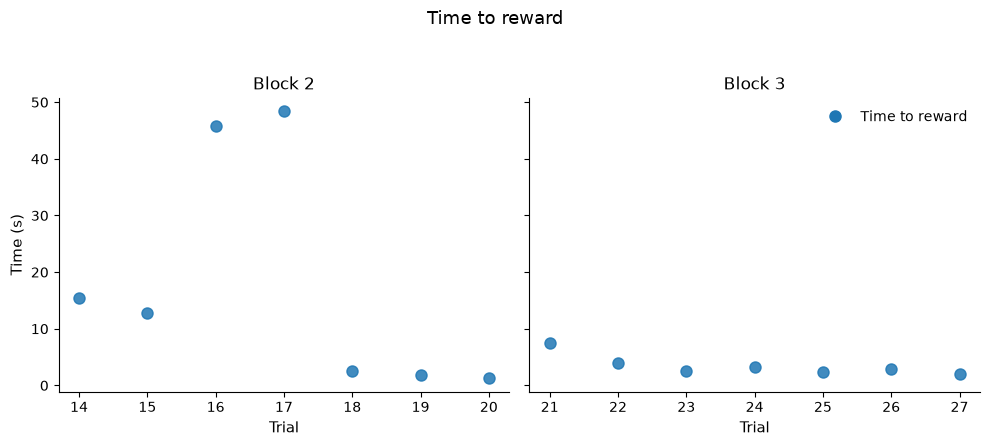

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
poster_color = 'tab:blue'

for ax, block in zip(axes, [2, 3]):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    trials, quiescence_value, response_value = bp._fetch_quiescence_response(experiment, key)
    ax.plot(trials, response_value, 'o', color=poster_color, markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(f'Block {block}', fontsize=12)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)

axes[0].set_ylabel('Time (s)', fontsize=11)
response_handle = Line2D([0], [0], marker='o', linestyle='None', color=poster_color,
                          markersize=8, label='Time to reward')
axes[1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(alt_dir / 'v1_2panel_linear_singlecolor.png', dpi=300, bbox_inches='tight')
plt.show()

### v2: three panels (block 1/2/3), log scale, single color, dividing walls between panels

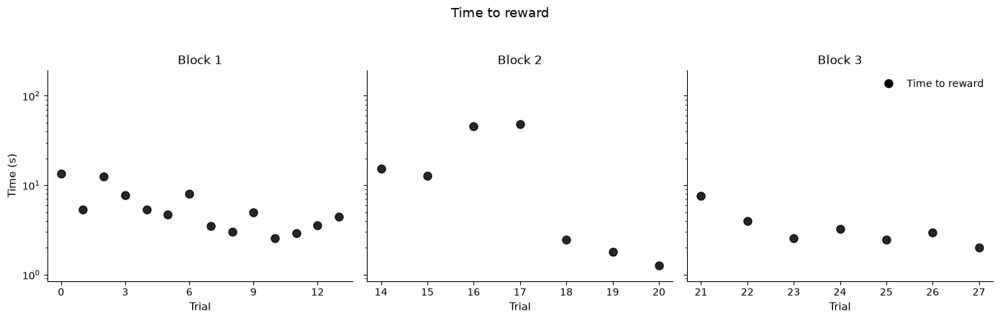

In [10]:
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()
poster_color = 'black'

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, (label, trials, response_value) in zip(axes, group_data):
    ax.plot(trials, response_value, 'o', color=poster_color, markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(label, fontsize=12)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)

axes[0].set_ylabel('Time (s)', fontsize=11)
response_handle = Line2D([0], [0], marker='o', linestyle='None', color=poster_color,
                          markersize=8, label='Time to reward')
axes[-1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(alt_dir / 'v2_3panel_log_singlecolor_walls.png', dpi=300, bbox_inches='tight')
plt.show()

#### Target area (Posterior-Anterior, g) for each block used above

Block 1 is the merged block 0+1 group; its target area here is taken from block 1.

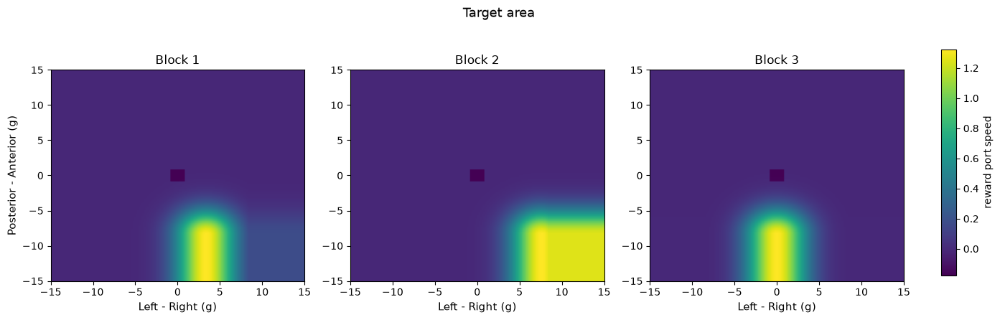

In [11]:
target_blocks = [('Block 1', 1), ('Block 2', 2), ('Block 3', 3)]

lut_data = []
for label, block in target_blocks:
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)
    lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    lut_data.append((label, lut, lut_extent))

lut_vmin = min(np.min(l) for _, l, _ in lut_data)
lut_vmax = max(np.max(l) for _, l, _ in lut_data)
uniform_range = uniform_force_range

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
im = None
for ax, (label, lut, lut_extent) in zip(axes, lut_data):
    lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_range)
    im = ax.imshow(lut_disp, extent=uniform_range, origin='lower', cmap='viridis', aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
    ax.set_xlim(uniform_range[:2])
    ax.set_ylim(uniform_range[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=11)
    ax.set_title(label, fontsize=12)

axes[0].set_ylabel('Posterior - Anterior (g)', fontsize=11)
fig.suptitle('Target area', fontsize=13)
fig.tight_layout(rect=[0, 0, 0.92, 0.94])
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
fig.colorbar(im, cax=cbar_ax, label='reward port speed')
fig.savefig(alt_dir / 'v2_3panel_target_area.png', dpi=300, bbox_inches='tight')
plt.show()

#### Force trajectories (Posterior-Anterior, g) for each block used above

Same block grouping as the target-area figure (block 1 = block 0+1 combined). Every
trial in each group is gaussian-filtered (sigma = 3 ms) and restricted to the response
epoch only (quiescence and reward excluded), then plotted, colored by trial position
within the group (early=blue, late=red).

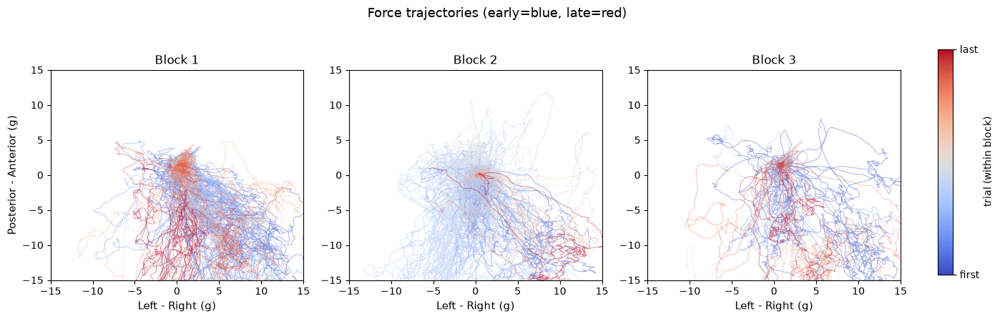

In [12]:
def lr_pa_traces_for_blocks(subject_id, session, blocks, filter_sigma_ms=3.0, epochs=('response',)):
    all_lr, all_pa = [], []
    for block in blocks:
        key = {'subject_id': subject_id, 'session': session, 'block': block}
        task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
        _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

        f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                    * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0})
        f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                    & {**key, 'force_axis_idx': 1})
        force_trials, force_trace_times, f0_ = f0_query.fetch('trial', 'force_trace_time', 'force_trace_value', order_by='trial')
        f1_ = f1_query.fetch('force_trace_value', order_by='trial')
        f0_baseline = np.median(np.concatenate(f0_))
        f1_baseline = np.median(np.concatenate(f1_))
        f0 = [f - f0_baseline for f in f0_]
        f1 = [f - f1_baseline for f in f1_]
        lr_traces, pa_traces = bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)

        sample_interval_s = bp._estimate_sample_interval(force_trace_times)
        filter_sigma = bp.ms_to_samples_float(filter_sigma_ms, sample_interval_s, minimum=1e-6)
        lr_traces, pa_traces = bp._filter_traces(lr_traces, pa_traces, 'gaussian', sigma=filter_sigma)

        epoch_windows = bp._fetch_epoch_windows(experiment, key)
        lr_traces, pa_traces = bp._filter_traces_by_epochs(force_trials, force_trace_times, lr_traces, pa_traces,
                                                            epoch_windows, epochs)

        all_lr.extend(lr_traces)
        all_pa.extend(pa_traces)
    return all_lr, all_pa


target_blocks = [('Block 1', [0, 1]), ('Block 2', [2]), ('Block 3', [3])]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (label, blocks) in zip(axes, target_blocks):
    lr_traces, pa_traces = lr_pa_traces_for_blocks(subject_id, session, blocks)
    bp._plot_force_trajectories(ax, lr_traces, pa_traces, uniform_force_range=uniform_force_range, title=None, ylabel=False, add_colorbar=False)
    ax.set_xlabel('Left - Right (g)', fontsize=11)
    ax.set_title(label, fontsize=12)

axes[0].set_ylabel('Posterior - Anterior (g)', fontsize=11)
fig.suptitle('Force trajectories (early=blue, late=red)', fontsize=13)
fig.tight_layout(rect=[0, 0, 0.92, 0.94])

sm_traj = bp.cm.ScalarMappable(cmap=bp.cm.coolwarm, norm=plt.Normalize(vmin=0, vmax=1))
sm_traj.set_array([])
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(sm_traj, cax=cbar_ax, label='trial (within block)')
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['first', 'last'])

fig.savefig(alt_dir / 'v2_3panel_force_trajectories.png', dpi=300, bbox_inches='tight')
plt.show()

### v3: three panels (block 1/2/3), log scale, single color, no dividing walls

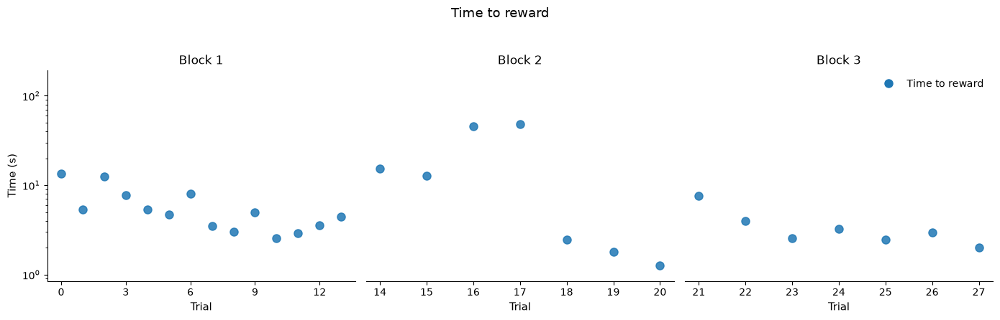

In [13]:
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()
poster_color = 'tab:blue'

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for i, (ax, (label, trials, response_value)) in enumerate(zip(axes, group_data)):
    ax.plot(trials, response_value, 'o', color=poster_color, markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(label, fontsize=12)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)
    if i > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False, which='both')

axes[0].set_ylabel('Time (s)', fontsize=11)
response_handle = Line2D([0], [0], marker='o', linestyle='None', color=poster_color,
                          markersize=8, label='Time to reward')
axes[-1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(alt_dir / 'v3_3panel_log_singlecolor_nowalls.png', dpi=300, bbox_inches='tight')
plt.show()

### v4: one panel, log scale, all blocks color-coded together

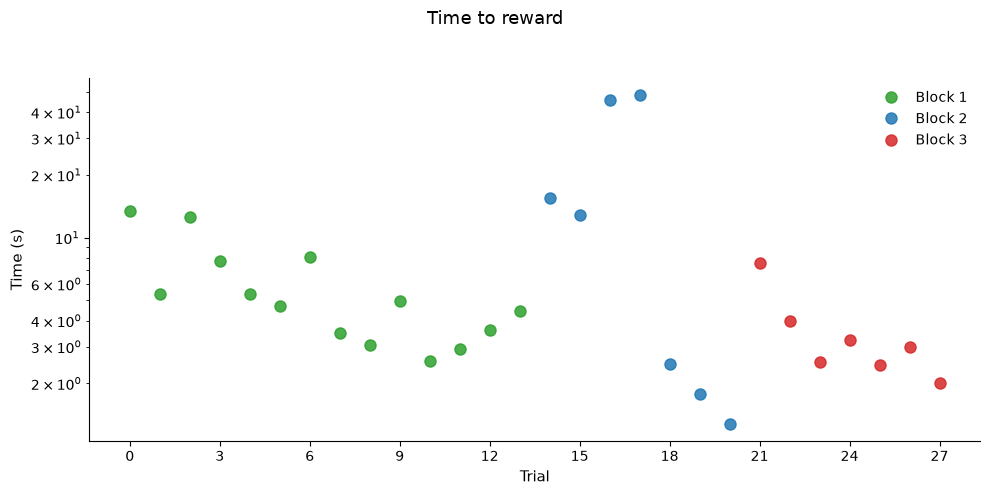

In [14]:
block_groups_colored = [('Block 1', [0, 1], 'tab:green'), ('Block 2', [2], 'tab:blue'), ('Block 3', [3], 'tab:red')]

fig, ax = plt.subplots(figsize=(10, 5))
for label, blocks, color in block_groups_colored:
    trials_parts, response_parts = [], []
    for block in blocks:
        key = {'subject_id': subject_id, 'session': session, 'block': block}
        t, _, r = bp._fetch_quiescence_response(experiment, key)
        trials_parts.append(t)
        response_parts.append(r)
    trials = np.concatenate(trials_parts)
    response_value = np.concatenate(response_parts)
    order = np.argsort(trials)
    ax.plot(trials[order], response_value[order], 'o', color=color, markersize=8, alpha=0.85, label=label)

ax.set_yscale('log')
ax.set_xlabel('Trial', fontsize=11)
ax.set_ylabel('Time (s)', fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=10)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=10))
ax.legend(loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(alt_dir / 'v4_1panel_log_colorcoded.png', dpi=300, bbox_inches='tight')
plt.show()

### v5: three panels (block 1/2/3), log scale, color-coded, no dividing walls (current main figure)

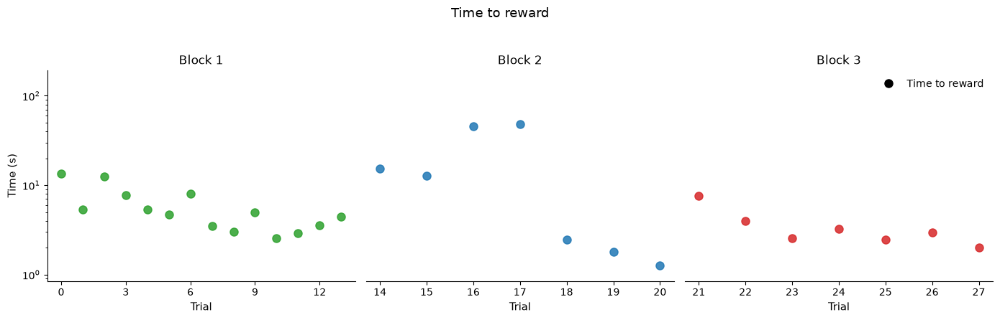

In [15]:
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()
block_colors_3 = ['tab:green', 'tab:blue', 'tab:red']

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for i, (ax, (label, trials, response_value)) in enumerate(zip(axes, group_data)):
    ax.plot(trials, response_value, 'o', color=block_colors_3[i], markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(label, fontsize=12)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)
    if i > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False, which='both')

axes[0].set_ylabel('Time (s)', fontsize=11)
response_handle = Line2D([0], [0], marker='o', linestyle='None', color='black',
                          markersize=8, label='Time to reward')
axes[-1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(alt_dir / 'v5_3panel_log_colorcoded_nowalls.png', dpi=300, bbox_inches='tight')
plt.show()

#### Force trajectories - selected trials only

Same block grouping (block 1 / block 2 / block 3), but restricted to a hand-picked
subset of trials per block: block 1 -> trials 7, 8, 11, 13; block 2 -> trials 15, 16,
19, 20; block 3 -> trials 21, 22, 23, 27. Response epoch only, gaussian-filtered
(sigma = 3 ms), using the same `lr_pa_traces_for_trials` helper defined above.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\v2_3panel_force_trajectories_selected_trials.png

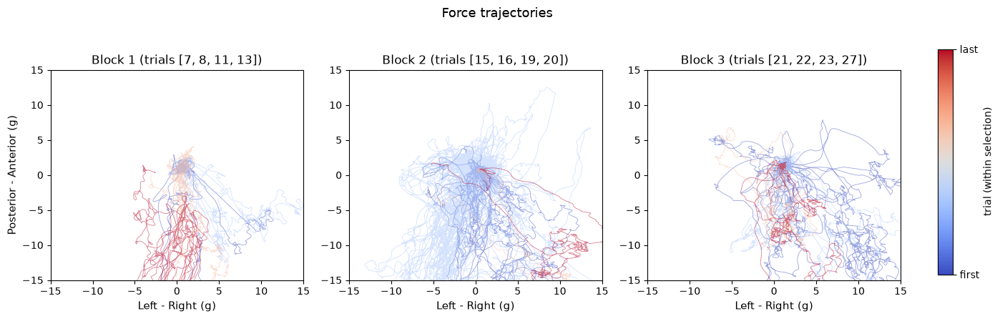

In [16]:
trials_selected_by_block = {1: [7, 8, 11, 13], 2: [15, 16, 19, 20], 3: [21, 22, 23, 27]}
labels_by_block = {1: 'Block 1', 2: 'Block 2', 3: 'Block 3'}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (block, trials) in zip(axes, trials_selected_by_block.items()):
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)
    bp._plot_force_trajectories(ax, lr_traces, pa_traces, uniform_force_range=uniform_force_range, title=None, ylabel=False, add_colorbar=False)
    ax.set_xlabel('Left - Right (g)', fontsize=11)
    ax.set_title(f'{labels_by_block[block]} (trials {trials})', fontsize=12)

axes[0].set_ylabel('Posterior - Anterior (g)', fontsize=11)
fig.suptitle('Force trajectories', fontsize=13)
fig.tight_layout(rect=[0, 0, 0.92, 0.94])

sm_traj = bp.cm.ScalarMappable(cmap=bp.cm.coolwarm, norm=plt.Normalize(vmin=0, vmax=1))
sm_traj.set_array([])
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(sm_traj, cax=cbar_ax, label='trial (within selection)')
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['first', 'last'])

fig_dir_path = alt_dir / 'v2_3panel_force_trajectories_selected_trials.png'
fig.savefig(fig_dir_path, dpi=300, bbox_inches='tight')
print('Saved to', fig_dir_path)
plt.show()

## Figure request: Trial 14 - lickport movement type vs. force signature

Three-panel figure centered on trial 14, block 2:

- **Panel 1**: lickport position (mm) vs. absolute session time, spanning trial
  14's response and reward epochs plus trial 15's quiescence epoch (the quiescence
  that follows chronologically, since trial 14 has no quiescence left to show after
  its own response - quiescence always precedes a response, so the one that
  continues this timeline forward is trial 15's). Background shading marks which
  epoch is which (quiescence/response/reward), and a dashed horizontal line marks
  the lickport threshold position for this block.
- **Panel 2**: force trajectory (Left-Right vs. Posterior-Anterior, g), gaussian-
  filtered (sigma = 3 ms), trial 14's response period only, fixed to a uniform
  +/-10g axis range.
- **Panel 3**: this block's target area (reward port speed), on the same +/-10g
  axis range as panel 2, for direct spatial comparison.

Panels 1 and 2 are colored by the same two-way classification of lickport motion
during trial 14's response period, derived once from the lickport trace and then
matched onto the force trace by timestamp (panel 1's line is colored the same way
over its full extended range, reclassified over that longer window):

1. The lickport position is lightly gaussian-smoothed (sigma = 20 ms) and its
   time-derivative (velocity, mm/s) is computed.
2. Samples where `|velocity|` exceeds the 75th percentile of `|velocity|` (computed
   separately for each window shown) are labeled **step-like** (fast, discrete-jump
   motion); the rest are labeled **continuous** (slow, gradual motion). This
   threshold is window-relative rather than a fixed absolute value.
3. Each force-trace sample (panel 2) is assigned the lickport label of the most
   recent lickport sample at or before its own timestamp (nearest-preceding
   match).

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial14_lickport_vs_force_signature.png

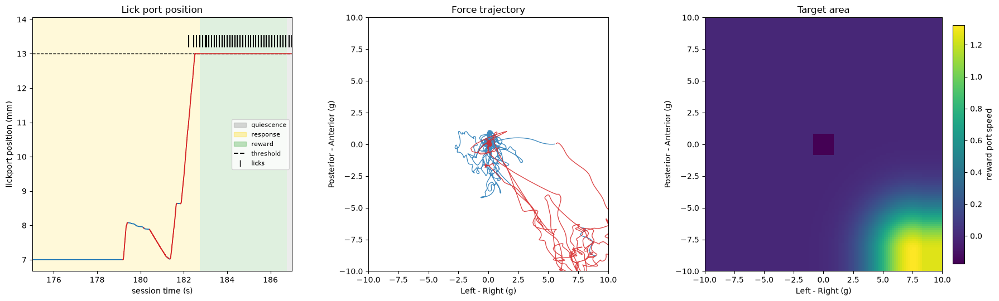

In [17]:
import pandas as pd

trial_of_interest = 14
block_of_interest = 2
t14_key = {'subject_id': subject_id, 'session': session, 'trial': trial_of_interest}
t15_key = {'subject_id': subject_id, 'session': session, 'trial': trial_of_interest + 1}
b2_key = {'subject_id': subject_id, 'session': session, 'block': block_of_interest}
trial_uniform_range = np.array([-1, 1, -1, 1]) * 10  # g
window_start, window_end = 175.0, 187.0  # session time (s), the slice actually shown


def classify_lickport_motion(t, v, smooth_sigma_ms=20.0, percentile=75.0):
    """Gaussian-smooth v(t), take its time-derivative, and label samples whose
    |velocity| exceeds the given percentile (computed over this window) as
    step-like (True) vs. continuous (False)."""
    sample_interval_s = np.median(np.diff(t))
    sigma_samples = bp.ms_to_samples_float(smooth_sigma_ms, sample_interval_s, minimum=1e-6)
    v_smooth = bp._filter_trace(v, 'gaussian', sigma=sigma_samples)
    velocity = np.gradient(v_smooth, t)
    threshold = np.percentile(np.abs(velocity), percentile)
    return np.abs(velocity) > threshold


t14_start, t14_end = (experiment.SessionTrial() & t14_key).fetch1('trial_start_time', 'trial_end_time')
t14_start, t14_end = float(t14_start), float(t14_end)
t15_start = float((experiment.SessionTrial() & t15_key).fetch1('trial_start_time'))

go_time = float((experiment.TrialEvent() & {**t14_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))
threshold_time = float((experiment.TrialEvent() & {**t14_key, 'trial_event_type': 'threshold crossing'}).fetch1('trial_event_time'))
go15_time = float((experiment.TrialEvent() & {**t15_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))

abs_go14 = t14_start + go_time
abs_threshold14 = t14_start + threshold_time
abs_t14_end = t14_end  # == t15_start, no gap between trials
abs_go15 = t15_start + go15_time

# --- lickport position: trial 14 response+reward, then trial 15 quiescence ---
lp14_time, lp14_val = (experiment.TrialRewardPortPosition() & t14_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp14_time = np.asarray(lp14_time, float)
lp14_val = np.asarray(lp14_val, float)

threshold_position = lp14_val[np.clip(np.searchsorted(lp14_time, threshold_time, side='right') - 1, 0, len(lp14_val) - 1)]

extended14_mask = (lp14_time >= go_time) & (lp14_time <= (t14_end - t14_start))
t14_ext_abs = t14_start + lp14_time[extended14_mask]
v14_ext = lp14_val[extended14_mask]

lp15_time, lp15_val = (experiment.TrialRewardPortPosition() & t15_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp15_time = np.asarray(lp15_time, float)
lp15_val = np.asarray(lp15_val, float)
quiescence15_mask = (lp15_time >= 0) & (lp15_time <= go15_time)
t15_ext_abs = t15_start + lp15_time[quiescence15_mask]
v15_ext = lp15_val[quiescence15_mask]

lp_ext_df = pd.concat([
    pd.DataFrame({'t': t14_ext_abs, 'v': v14_ext}),
    pd.DataFrame({'t': t15_ext_abs, 'v': v15_ext}),
]).groupby('t', as_index=False).last()
t_lp_ext, v_lp_ext = lp_ext_df['t'].values, lp_ext_df['v'].values
is_step_ext = classify_lickport_motion(t_lp_ext, v_lp_ext)  # shared by panels 1 and 2

# --- force trace (LR/PA), trial 14 + trial 15, gaussian-filtered (sigma=3ms) each ---
task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & b2_key).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)


def fetch_trial_lr_pa(trial_key, trial_start_abs):
    f0_time, f0_val = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                        & {**trial_key, 'force_axis_idx': 0}).fetch1('force_trace_time', 'force_trace_value')
    f1_val = (experiment.TrialForceTrace.TrialForceAxis() & {**trial_key, 'force_axis_idx': 1}).fetch1('force_trace_value')
    f0_time = np.asarray(f0_time, float)
    f0_val = np.asarray(f0_val, float) - np.median(f0_val)
    f1_val = np.asarray(f1_val, float) - np.median(f1_val)
    lr, pa = bp._lr_pa_traces([f0_val], [f1_val], lr_idx, pa_idx, lr_sign, pa_sign)
    lr, pa = lr[0], pa[0]
    sample_interval_s = bp._estimate_sample_interval([f0_time])
    sigma = bp.ms_to_samples_float(3.0, sample_interval_s, minimum=1e-6)
    (lr,), (pa,) = bp._filter_traces([lr], [pa], 'gaussian', sigma=sigma)
    return trial_start_abs + f0_time, lr, pa


f_time14, lr14, pa14 = fetch_trial_lr_pa(t14_key, t14_start)
f_time15, lr15, pa15 = fetch_trial_lr_pa(t15_key, t15_start)
f_time_all = np.concatenate([f_time14, f_time15])
lr_all = np.concatenate([lr14, lr15])
pa_all = np.concatenate([pa14, pa15])

window_mask = (f_time_all >= window_start) & (f_time_all <= window_end) & (f_time_all < abs_threshold14)
f_time = f_time_all[window_mask]
lr_smooth, pa_smooth = lr_all[window_mask], pa_all[window_mask]

match_idx = np.clip(np.searchsorted(t_lp_ext, f_time, side='right') - 1, 0, len(is_step_ext) - 1)
force_is_step = is_step_ext[match_idx]

# --- target area (reward port speed LUT) for this trial's block ---
lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
lut_disp = bp._pad_lut_to_range(lut, lut_extent, trial_uniform_range)

# --- plot ---
color_continuous = 'tab:blue'
color_step = 'tab:red'

fig, (ax_lp, ax_force, ax_target) = plt.subplots(1, 3, figsize=(18, 5.5))

ax_lp.axvspan(abs_go14, abs_threshold14, color='gold', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_threshold14, abs_t14_end, color='tab:green', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_t14_end, abs_go15, color='gray', alpha=0.15, linewidth=0)
ax_lp.axhline(threshold_position, color='black', linestyle='--', linewidth=1)

v_lp_continuous = np.where(~is_step_ext, v_lp_ext, np.nan)
v_lp_step = np.where(is_step_ext, v_lp_ext, np.nan)
ax_lp.step(t_lp_ext, v_lp_continuous, where='post', color=color_continuous, linewidth=1.3)
ax_lp.step(t_lp_ext, v_lp_step, where='post', color=color_step, linewidth=1.3)

lick_times14 = np.asarray((experiment.TrialEvent() & {**t14_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_times15 = np.asarray((experiment.TrialEvent() & {**t15_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_abs = np.concatenate([t14_start + lick_times14, t15_start + lick_times15])
lick_abs = lick_abs[(lick_abs >= window_start) & (lick_abs <= window_end)]
y0, y1 = v_lp_ext.min(), v_lp_ext.max()
tick_height = 0.06 * (y1 - y0)
ax_lp.eventplot(lick_abs, orientation='horizontal', lineoffsets=y1 + tick_height, linelengths=tick_height, colors='black')

ax_lp.set_xlim(window_start, window_end)
ax_lp.set_xlabel('session time (s)')
ax_lp.set_ylabel('lickport position (mm)')
ax_lp.set_title('Lick port position')
ax_lp.legend(handles=[
    bp.Patch(color='gray', alpha=0.3, label='quiescence'),
    bp.Patch(color='gold', alpha=0.3, label='response'),
    bp.Patch(color='tab:green', alpha=0.3, label='reward'),
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=8, label='licks'),
], loc='center right', fontsize=8)

lr_continuous = np.where(~force_is_step, lr_smooth, np.nan)
pa_continuous = np.where(~force_is_step, pa_smooth, np.nan)
lr_step = np.where(force_is_step, lr_smooth, np.nan)
pa_step = np.where(force_is_step, pa_smooth, np.nan)
ax_force.plot(lr_continuous, pa_continuous, '-', color=color_continuous, linewidth=1, alpha=0.85)
ax_force.plot(lr_step, pa_step, '-', color=color_step, linewidth=1, alpha=0.85)
ax_force.set_xlim(trial_uniform_range[:2])
ax_force.set_ylim(trial_uniform_range[2:])
ax_force.set_xlabel('Left - Right (g)')
ax_force.set_ylabel('Posterior - Anterior (g)')
ax_force.set_title('Force trajectory')

im_target = ax_target.imshow(lut_disp, extent=trial_uniform_range, origin='lower', cmap='viridis', aspect='auto')
ax_target.set_xlim(trial_uniform_range[:2])
ax_target.set_ylim(trial_uniform_range[2:])
ax_target.set_xlabel('Left - Right (g)')
ax_target.set_ylabel('Posterior - Anterior (g)')
ax_target.set_title('Target area')
fig.colorbar(im_target, ax=ax_target, label='reward port speed', fraction=0.046, pad=0.04)

plt.tight_layout(w_pad=3.5)

# nudge the middle panel right, so its left gap (from the target-area panel,
# whose colorbar already eats into that margin) matches its right gap
pos = ax_force.get_position()
shift = 0.02
ax_force.set_position([pos.x0, pos.y0, pos.width - shift, pos.height])

out_path = alt_dir / f'trial{trial_of_interest}_lickport_vs_force_signature.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Combined poster figure: target area / time to reward / force trajectories

Three existing figures stacked into one, all sharing the same column widths (one
column per block group) so they line up for the poster:

1. **Target area** (top)
2. **Time to reward**, log scale (middle)
3. **Force trajectories, selected trials** (bottom)

Each row's colorbar (where it has one) sits in a dedicated fourth column so it
never eats into that row's plot width relative to the other rows.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_target_reward_trajectories_colored.png

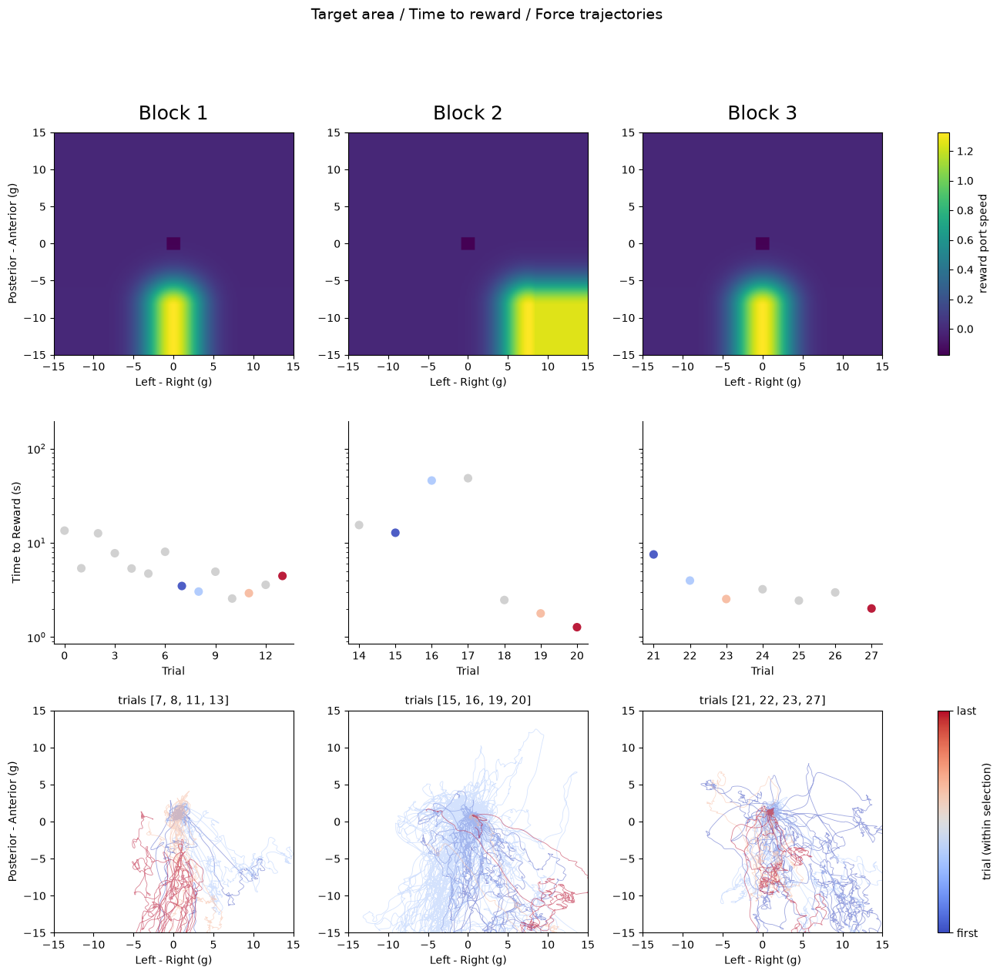

In [18]:
fig = plt.figure(figsize=(15, 13.5))
gs = plt.GridSpec(3, 4, figure=fig, width_ratios=[1, 1, 1, 0.05],
                   height_ratios=[1, 1, 1], hspace=0.3, wspace=0.3)

selected_by_label = {labels_by_block[b]: t for b, t in trials_selected_by_block.items()}

# --- row 0: target area ---
target_blocks = [('Block 1', 3), ('Block 2', 2), ('Block 3', 3)]
lut_data = []
for label, block in target_blocks:
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)
    lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    lut_data.append((label, lut, lut_extent))
lut_vmin = min(np.min(l) for _, l, _ in lut_data)
lut_vmax = max(np.max(l) for _, l, _ in lut_data)

im_target = None
axes_target = []
for col, (label, lut, lut_extent) in enumerate(lut_data):
    ax = fig.add_subplot(gs[0, col])
    lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_force_range)
    im_target = ax.imshow(lut_disp, extent=uniform_force_range, origin='lower', cmap='viridis',
                           aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
    ax.set_xlim(uniform_force_range[:2])
    ax.set_ylim(uniform_force_range[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_target.append(ax)
cax_target = fig.add_subplot(gs[0, 3])
fig.colorbar(im_target, cax=cax_target, label='reward port speed')

# big column headers, above row 0, instead of a title repeated on every panel
for ax, (label, _) in zip(axes_target, target_blocks):
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.008, label, ha='center', va='bottom', fontsize=18)

# --- row 1: time to reward (log scale); only the trials used in row 2 are colored
#     early=blue -> late=red (matching row 2's coloring), the rest are neutral gray ---
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()

axes_reward = []
for col, (label, trials, response_value) in enumerate(group_data):
    ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
    sel_trials = selected_by_label[label]
    n_sel = len(sel_trials)
    frac_by_trial = {t: i / max(n_sel - 1, 1) for i, t in enumerate(sel_trials)}
    dot_colors = [bp.cm.coolwarm(frac_by_trial[t]) if t in frac_by_trial else (0.8, 0.8, 0.8, 1.0)
                  for t in trials]
    ax.scatter(trials, response_value, c=dot_colors, s=64, alpha=0.9, edgecolor='none')
    ax.set_xlabel('Trial', fontsize=10)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if col == 0:
        ax.set_ylabel('Time to Reward (s)', fontsize=10)
    else:
        plt.setp(ax.get_yticklabels(), visible=False)
    axes_reward.append(ax)

# --- row 2: force trajectories, selected trials ---
axes_traj = []
for col, (block, trials) in enumerate(trials_selected_by_block.items()):
    ax = fig.add_subplot(gs[2, col])
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)
    bp._plot_force_trajectories(ax, lr_traces, pa_traces, uniform_force_range=uniform_force_range,
                                 title=None, ylabel=False, add_colorbar=False)
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    ax.set_title(f'trials {trials}', fontsize=11)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_traj.append(ax)
sm_traj = bp.cm.ScalarMappable(cmap=bp.cm.coolwarm, norm=plt.Normalize(vmin=0, vmax=1))
sm_traj.set_array([])
cax_traj = fig.add_subplot(gs[2, 3])
cbar_traj = fig.colorbar(sm_traj, cax=cax_traj, label='trial (within selection)')
cbar_traj.set_ticks([0, 1])
cbar_traj.set_ticklabels(['first', 'last'])

fig.suptitle('Target area / Time to reward / Force trajectories', fontsize=14, y=1.0)

out_path = alt_dir / 'combined_target_reward_trajectories_colored.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Combined poster figure, 20g uniform force range

Same figure as above, but with the axis range on the target-area and force-
trajectory rows widened from +/-15g to +/-20g.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_target_reward_trajectories_colored_20g.png

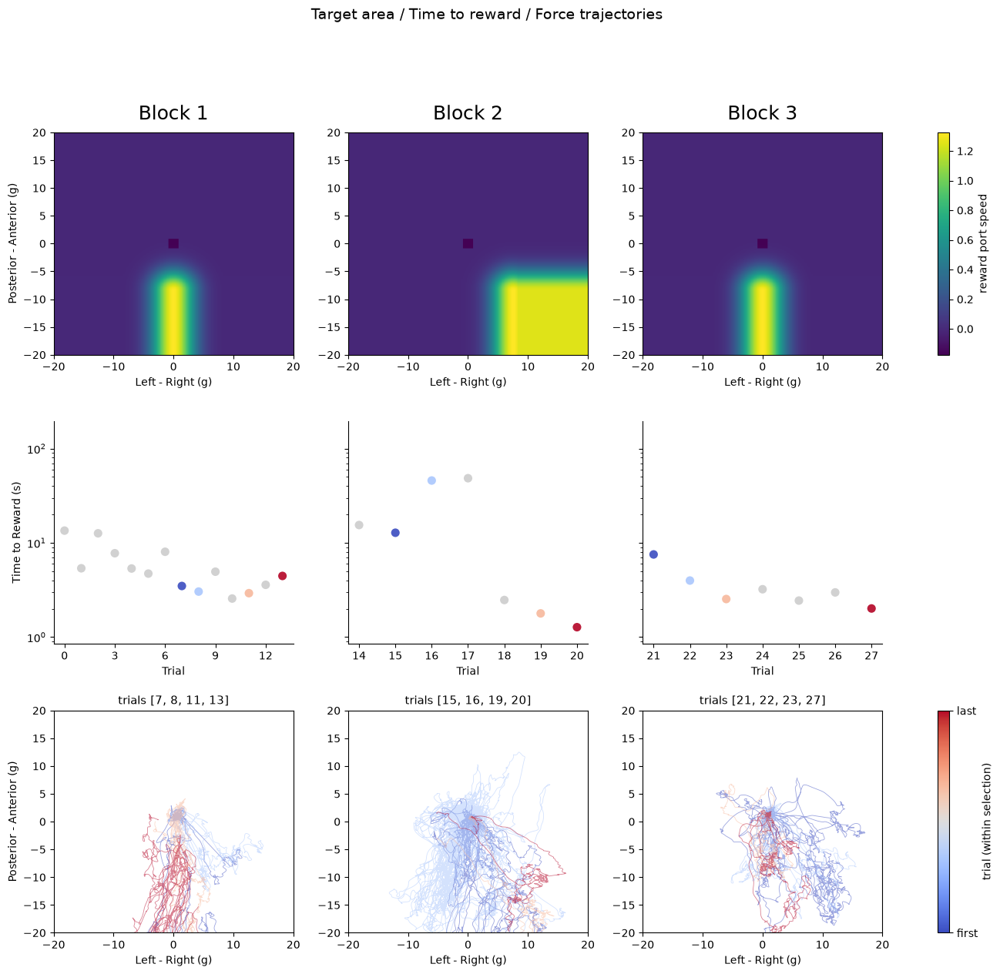

In [19]:
fig = plt.figure(figsize=(15, 13.5))
gs = plt.GridSpec(3, 4, figure=fig, width_ratios=[1, 1, 1, 0.05],
                   height_ratios=[1, 1, 1], hspace=0.3, wspace=0.3)

selected_by_label = {labels_by_block[b]: t for b, t in trials_selected_by_block.items()}
uniform_force_range_20g = np.array([-1, 1, -1, 1]) * 20  # g

# --- row 0: target area ---
target_blocks = [('Block 1', 3), ('Block 2', 2), ('Block 3', 3)]
lut_data = []
for label, block in target_blocks:
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)
    lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    lut_data.append((label, lut, lut_extent))
lut_vmin = min(np.min(l) for _, l, _ in lut_data)
lut_vmax = max(np.max(l) for _, l, _ in lut_data)

im_target = None
axes_target = []
for col, (label, lut, lut_extent) in enumerate(lut_data):
    ax = fig.add_subplot(gs[0, col])
    lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_force_range_20g)
    im_target = ax.imshow(lut_disp, extent=uniform_force_range_20g, origin='lower', cmap='viridis',
                           aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
    ax.set_xlim(uniform_force_range_20g[:2])
    ax.set_ylim(uniform_force_range_20g[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_target.append(ax)
cax_target = fig.add_subplot(gs[0, 3])
fig.colorbar(im_target, cax=cax_target, label='reward port speed')

# big column headers, above row 0, instead of a title repeated on every panel
for ax, (label, _) in zip(axes_target, target_blocks):
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.008, label, ha='center', va='bottom', fontsize=18)

# --- row 1: time to reward (log scale); only the trials used in row 2 are colored
#     early=blue -> late=red (matching row 2's coloring), the rest are neutral gray ---
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()

axes_reward = []
for col, (label, trials, response_value) in enumerate(group_data):
    ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
    sel_trials = selected_by_label[label]
    n_sel = len(sel_trials)
    frac_by_trial = {t: i / max(n_sel - 1, 1) for i, t in enumerate(sel_trials)}
    dot_colors = [bp.cm.coolwarm(frac_by_trial[t]) if t in frac_by_trial else (0.8, 0.8, 0.8, 1.0)
                  for t in trials]
    ax.scatter(trials, response_value, c=dot_colors, s=64, alpha=0.9, edgecolor='none')
    ax.set_xlabel('Trial', fontsize=10)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if col == 0:
        ax.set_ylabel('Time to Reward (s)', fontsize=10)
    else:
        plt.setp(ax.get_yticklabels(), visible=False)
    axes_reward.append(ax)

# --- row 2: force trajectories, selected trials ---
axes_traj = []
for col, (block, trials) in enumerate(trials_selected_by_block.items()):
    ax = fig.add_subplot(gs[2, col])
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)
    bp._plot_force_trajectories(ax, lr_traces, pa_traces, uniform_force_range=uniform_force_range_20g,
                                 title=None, ylabel=False, add_colorbar=False)
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    ax.set_title(f'trials {trials}', fontsize=11)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_traj.append(ax)
sm_traj = bp.cm.ScalarMappable(cmap=bp.cm.coolwarm, norm=plt.Normalize(vmin=0, vmax=1))
sm_traj.set_array([])
cax_traj = fig.add_subplot(gs[2, 3])
cbar_traj = fig.colorbar(sm_traj, cax=cax_traj, label='trial (within selection)')
cbar_traj.set_ticks([0, 1])
cbar_traj.set_ticklabels(['first', 'last'])

fig.suptitle('Target area / Time to reward / Force trajectories', fontsize=14, y=1.0)

out_path = alt_dir / 'combined_target_reward_trajectories_colored_20g.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## New subject: human_11, blocks 0/1/3

Same combined layout as `combined_target_reward_trajectories_colored`, but for a new
subject/session (`human_11`, session 0), using blocks 0, 1 and 3 directly (no block
merging this time - each column is exactly one raw block). Each block's selected
trials are its first 2 and last 2 trials.

**Force trajectory fix:** for this subject, the lever position never resets to (0, 0)
between trials - the raw sensor value at the end of one trial carries straight over
as the start of the next (confirmed: trial N's last force sample matches trial N+1's
first sample almost exactly). Baselining each trial by its own whole-trial median (as
done for M029) works there, but here it badly distorts the trajectories, because
reward-consumption movements often dominate a trial's samples and skew that median
away from the trial's actual resting position. The fix used below instead baselines
each trial using the median of its own **quiescence-period** samples (before the 'go'
event) - the one point in every trial that is, by task design, the at-rest reference
the trajectory should start from - falling back to the whole-trial median only for a
trial with no quiescence samples at all.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_human_11_target_reward_trajectories.png

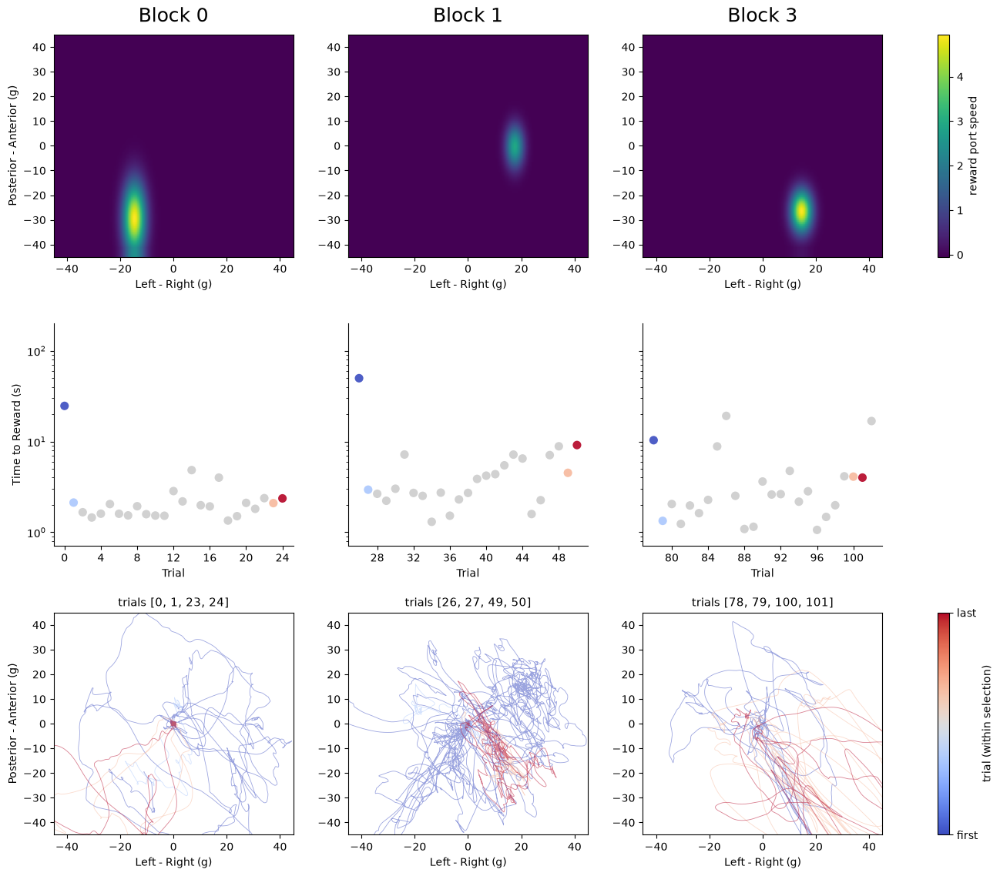

In [20]:
subject_id_h11 = 'human_11'
session_h11 = 0
uniform_force_range_h11 = np.array([-1, 1, -1, 1]) * 45  # g
block_groups_h11 = [('Block 0', 0), ('Block 1', 1), ('Block 3', 3)]
block_ranges_h11 = {}
for label, block in block_groups_h11:
    bt = (experiment.BehaviorTrial() & {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}).fetch('trial')
    block_ranges_h11[block] = (int(bt.min()), int(bt.max()))

# selection per block: the first 2 and last 2 trials.
trials_selected_h11 = {}
for label, block in block_groups_h11:
    key = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}
    trials, _, response_value = bp._fetch_quiescence_response(experiment, key)
    order = np.argsort(trials)
    trials, response_value = trials[order], response_value[order]
    trials_selected_h11[block] = sorted(trials[:2].tolist() + trials[-2:].tolist())
trials_selected_h11[3] = [78, 79, 100, 101]  # hand-picked for the last block


def lr_pa_traces_quiescence_baseline(subject_id, session, block, trials, filter_sigma_ms=3.0, epochs=('response',)):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
    _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

    trial_restriction = [{'trial': int(t)} for t in trials]
    f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0} & trial_restriction)
    f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                & {**key, 'force_axis_idx': 1} & trial_restriction)
    force_trials, force_trace_times, f0_ = f0_query.fetch('trial', 'force_trace_time', 'force_trace_value', order_by='trial')
    f1_ = f1_query.fetch('force_trace_value', order_by='trial')

    go_by_trial = bp._event_time_by_trial(experiment, key, 'go')
    f0, f1 = [], []
    for trial, t, v0, v1 in zip(force_trials, force_trace_times, f0_, f1_):
        t = np.asarray(t, float)
        v0 = np.asarray(v0, float)
        v1 = np.asarray(v1, float)
        go_t = go_by_trial.get(int(trial))
        q_mask = (t < go_t) if go_t is not None else np.zeros_like(t, dtype=bool)
        if q_mask.any():
            b0, b1 = np.median(v0[q_mask]), np.median(v1[q_mask])
        else:
            b0, b1 = np.median(v0), np.median(v1)
        f0.append(v0 - b0)
        f1.append(v1 - b1)

    lr_traces, pa_traces = bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)

    sample_interval_s = bp._estimate_sample_interval(force_trace_times)
    filter_sigma = bp.ms_to_samples_float(filter_sigma_ms, sample_interval_s, minimum=1e-6)
    lr_traces, pa_traces = bp._filter_traces(lr_traces, pa_traces, 'gaussian', sigma=filter_sigma)

    epoch_windows = bp._fetch_epoch_windows(experiment, key)
    lr_traces, pa_traces = bp._filter_traces_by_epochs(force_trials, force_trace_times, lr_traces, pa_traces,
                                                        epoch_windows, epochs)
    return lr_traces, pa_traces


fig = plt.figure(figsize=(15, 13.5))
gs = plt.GridSpec(3, 4, figure=fig, width_ratios=[1, 1, 1, 0.05],
                   height_ratios=[1, 1, 1], hspace=0.3, wspace=0.3)

# --- row 0: target area ---
lut_data_h11 = []
for label, block in block_groups_h11:
    key = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id_h11, session_h11, task_setting_id)
    lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    lut_data_h11.append((label, lut, lut_extent))
lut_vmin = min(np.min(l) for _, l, _ in lut_data_h11)
lut_vmax = max(np.max(l) for _, l, _ in lut_data_h11)

im_target = None
axes_target = []
for col, (label, lut, lut_extent) in enumerate(lut_data_h11):
    ax = fig.add_subplot(gs[0, col])
    lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_force_range_h11)
    im_target = ax.imshow(lut_disp, extent=uniform_force_range_h11, origin='lower', cmap='viridis',
                           aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
    ax.set_xlim(uniform_force_range_h11[:2])
    ax.set_ylim(uniform_force_range_h11[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_target.append(ax)
cax_target = fig.add_subplot(gs[0, 3])
fig.colorbar(im_target, cax=cax_target, label='reward port speed')

for ax, (label, _) in zip(axes_target, block_groups_h11):
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.008, label, ha='center', va='bottom', fontsize=18)

# --- row 1: time to reward (log scale); only the trials used in row 2 are colored
#     early=blue -> late=red (matching row 2's coloring), the rest are neutral gray ---
group_data_h11 = []
for label, block in block_groups_h11:
    key = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}
    trials, _, response_value = bp._fetch_quiescence_response(experiment, key)
    order = np.argsort(trials)
    group_data_h11.append((label, trials[order], response_value[order]))
all_response_h11 = np.concatenate([r for _, _, r in group_data_h11])
ymin_h11, ymax_h11 = all_response_h11.min(), all_response_h11.max()

selected_by_label_h11 = {label: trials_selected_h11[block] for label, block in block_groups_h11}

axes_reward = []
for col, (label, trials, response_value) in enumerate(group_data_h11):
    ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
    sel_trials = selected_by_label_h11[label]
    n_sel = len(sel_trials)
    frac_by_trial = {t: i / max(n_sel - 1, 1) for i, t in enumerate(sel_trials)}
    dot_colors = [bp.cm.coolwarm(frac_by_trial[t]) if t in frac_by_trial else (0.8, 0.8, 0.8, 1.0)
                  for t in trials]
    ax.scatter(trials, response_value, c=dot_colors, s=64, alpha=0.9, edgecolor='none')
    ax.set_xlabel('Trial', fontsize=10)
    ax.set_yscale('log')
    ax.set_ylim(ymin_h11 / 1.5, ymax_h11 * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if col == 0:
        ax.set_ylabel('Time to Reward (s)', fontsize=10)
    else:
        plt.setp(ax.get_yticklabels(), visible=False)
    axes_reward.append(ax)

# --- row 2: force trajectories, selected trials, quiescence-baselined ---
axes_traj = []
for col, (label, block) in enumerate(block_groups_h11):
    trials = trials_selected_h11[block]
    ax = fig.add_subplot(gs[2, col])
    lr_traces, pa_traces = lr_pa_traces_quiescence_baseline(subject_id_h11, session_h11, block, trials)
    bp._plot_force_trajectories(ax, lr_traces, pa_traces, uniform_force_range=uniform_force_range_h11,
                                 title=None, ylabel=False, add_colorbar=False)
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    ax.set_title(f'trials {trials}', fontsize=11)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_traj.append(ax)
sm_traj = bp.cm.ScalarMappable(cmap=bp.cm.coolwarm, norm=plt.Normalize(vmin=0, vmax=1))
sm_traj.set_array([])
cax_traj = fig.add_subplot(gs[2, 3])
cbar_traj = fig.colorbar(sm_traj, cax=cax_traj, label='trial (within selection)')
cbar_traj.set_ticks([0, 1])
cbar_traj.set_ticklabels(['first', 'last'])

out_path = alt_dir / 'combined_human_11_target_reward_trajectories.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Combined poster figure, 20g range, first/last 2 trials per block

Same as the 20g combined figure above, but the force-trajectory (and matching
time-to-reward highlight) trials are each block's first 2 and last 2 trials,
instead of the earlier hand-picked selection: block 1 -> trials 0, 1, 12, 13;
block 2 -> trials 14, 15, 19, 20; block 3 -> trials 21, 22, 26, 27.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_target_reward_trajectories_colored_20g_firstlast.png

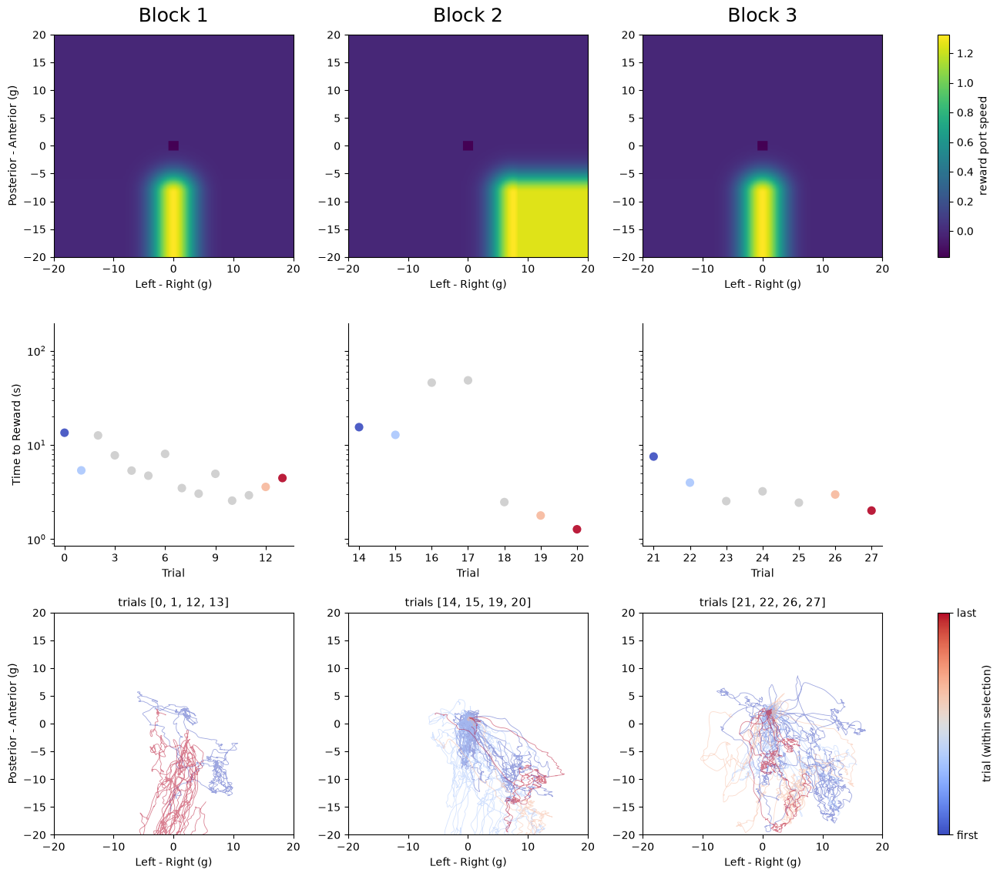

In [21]:
fig = plt.figure(figsize=(15, 13.5))
gs = plt.GridSpec(3, 4, figure=fig, width_ratios=[1, 1, 1, 0.05],
                   height_ratios=[1, 1, 1], hspace=0.3, wspace=0.3)

trials_first_last_by_block = {1: [0, 1, 12, 13], 2: [14, 15, 19, 20], 3: [21, 22, 26, 27]}
selected_by_label = {labels_by_block[b]: t for b, t in trials_first_last_by_block.items()}
uniform_force_range_20g = np.array([-1, 1, -1, 1]) * 20  # g

# --- row 0: target area ---
target_blocks = [('Block 1', 3), ('Block 2', 2), ('Block 3', 3)]
lut_data = []
for label, block in target_blocks:
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)
    lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    lut_data.append((label, lut, lut_extent))
lut_vmin = min(np.min(l) for _, l, _ in lut_data)
lut_vmax = max(np.max(l) for _, l, _ in lut_data)

im_target = None
axes_target = []
for col, (label, lut, lut_extent) in enumerate(lut_data):
    ax = fig.add_subplot(gs[0, col])
    lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_force_range_20g)
    im_target = ax.imshow(lut_disp, extent=uniform_force_range_20g, origin='lower', cmap='viridis',
                           aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
    ax.set_xlim(uniform_force_range_20g[:2])
    ax.set_ylim(uniform_force_range_20g[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_target.append(ax)
cax_target = fig.add_subplot(gs[0, 3])
fig.colorbar(im_target, cax=cax_target, label='reward port speed')

# big column headers, above row 0, instead of a title repeated on every panel
for ax, (label, _) in zip(axes_target, target_blocks):
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.008, label, ha='center', va='bottom', fontsize=18)

# --- row 1: time to reward (log scale); only the trials used in row 2 are colored
#     early=blue -> late=red (matching row 2's coloring), the rest are neutral gray ---
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()

axes_reward = []
for col, (label, trials, response_value) in enumerate(group_data):
    ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
    sel_trials = selected_by_label[label]
    n_sel = len(sel_trials)
    frac_by_trial = {t: i / max(n_sel - 1, 1) for i, t in enumerate(sel_trials)}
    dot_colors = [bp.cm.coolwarm(frac_by_trial[t]) if t in frac_by_trial else (0.8, 0.8, 0.8, 1.0)
                  for t in trials]
    ax.scatter(trials, response_value, c=dot_colors, s=64, alpha=0.9, edgecolor='none')
    ax.set_xlabel('Trial', fontsize=10)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if col == 0:
        ax.set_ylabel('Time to Reward (s)', fontsize=10)
    else:
        plt.setp(ax.get_yticklabels(), visible=False)
    axes_reward.append(ax)

# --- row 2: force trajectories, selected trials ---
axes_traj = []
for col, (block, trials) in enumerate(trials_first_last_by_block.items()):
    ax = fig.add_subplot(gs[2, col])
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)
    bp._plot_force_trajectories(ax, lr_traces, pa_traces, uniform_force_range=uniform_force_range_20g,
                                 title=None, ylabel=False, add_colorbar=False)
    ax.set_xlabel('Left - Right (g)', fontsize=10)
    ax.set_title(f'trials {trials}', fontsize=11)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=10)
    axes_traj.append(ax)
sm_traj = bp.cm.ScalarMappable(cmap=bp.cm.coolwarm, norm=plt.Normalize(vmin=0, vmax=1))
sm_traj.set_array([])
cax_traj = fig.add_subplot(gs[2, 3])
cbar_traj = fig.colorbar(sm_traj, cax=cax_traj, label='trial (within selection)')
cbar_traj.set_ticks([0, 1])
cbar_traj.set_ticklabels(['first', 'last'])

out_path = alt_dir / 'combined_target_reward_trajectories_colored_20g_firstlast.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Figure request: M029, day 31 (2026-09-14), trial 48

Same 3-panel design as `trial14_lickport_vs_force_signature` (lickport position /
force trajectory / target area, colored continuous vs. step-like, epoch-shaded,
threshold line, lick ticks), but for a different subject/session/trial: M029,
session 31 (2026-09-14), trial 48 (block 3).

**Target area panel:** per request, this reuses the exact same heatmap as the
original trial-14 figure (M029, session 25, block 2) rather than trial 48's own
block/target - the force-trajectory panel still uses trial 48's own force-axis
calibration (session 31, block 3), since that's what the actual plotted data needs.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial48_s31_lickport_vs_force_signature.png

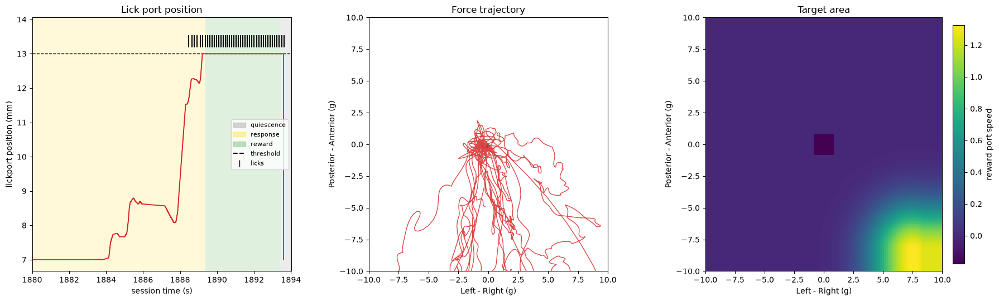

In [22]:
import pandas as pd

trial_of_interest_48 = 48
subject_id_48 = 'M029'
session_48 = 31
block_of_interest_48 = 3
t48_key = {'subject_id': subject_id_48, 'session': session_48, 'trial': trial_of_interest_48}
t49_key = {'subject_id': subject_id_48, 'session': session_48, 'trial': trial_of_interest_48 + 1}
b48_key = {'subject_id': subject_id_48, 'session': session_48, 'block': block_of_interest_48}
trial_uniform_range_48 = np.array([-1, 1, -1, 1]) * 10  # g

t48_start, t48_end = (experiment.SessionTrial() & t48_key).fetch1('trial_start_time', 'trial_end_time')
t48_start, t48_end = float(t48_start), float(t48_end)
t49_start = float((experiment.SessionTrial() & t49_key).fetch1('trial_start_time'))

go_time_48 = float((experiment.TrialEvent() & {**t48_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))
threshold_time_48 = float((experiment.TrialEvent() & {**t48_key, 'trial_event_type': 'threshold crossing'}).fetch1('trial_event_time'))
go49_time = float((experiment.TrialEvent() & {**t49_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))

abs_go48 = t48_start + go_time_48
abs_threshold48 = t48_start + threshold_time_48
abs_t48_end = t48_end  # == t49_start, no gap between trials
abs_go49 = t49_start + go49_time
window_start_48, window_end_48 = 1880.0, abs_go49  # cropped, so the panel isn't dominated by the slow early part of the response

# --- lickport position: trial 48 response+reward, then trial 49 quiescence ---
lp48_time, lp48_val = (experiment.TrialRewardPortPosition() & t48_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp48_time = np.asarray(lp48_time, float)
lp48_val = np.asarray(lp48_val, float)

threshold_position_48 = lp48_val[np.clip(np.searchsorted(lp48_time, threshold_time_48, side='right') - 1, 0, len(lp48_val) - 1)]

extended48_mask = (lp48_time >= go_time_48) & (lp48_time <= (t48_end - t48_start))
t48_ext_abs = t48_start + lp48_time[extended48_mask]
v48_ext = lp48_val[extended48_mask]

lp49_time, lp49_val = (experiment.TrialRewardPortPosition() & t49_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp49_time = np.asarray(lp49_time, float)
lp49_val = np.asarray(lp49_val, float)
quiescence49_mask = (lp49_time >= 0) & (lp49_time <= go49_time)
t49_ext_abs = t49_start + lp49_time[quiescence49_mask]
v49_ext = lp49_val[quiescence49_mask]

lp_ext_df_48 = pd.concat([
    pd.DataFrame({'t': t48_ext_abs, 'v': v48_ext}),
    pd.DataFrame({'t': t49_ext_abs, 'v': v49_ext}),
]).groupby('t', as_index=False).last()
t_lp_ext_48, v_lp_ext_48 = lp_ext_df_48['t'].values, lp_ext_df_48['v'].values
is_step_ext_48 = classify_lickport_motion(t_lp_ext_48, v_lp_ext_48)  # shared by panels 1 and 2

# --- target area (reward port speed LUT): reused as-is from the trial-14 figure
#     (M029, session 25, block 2), per request, instead of trial 48's own block ---
target_key_reused = {'subject_id': 'M029', 'session': 25, 'block': 2}
task_setting_id_target, target_force_lut_reused = (experiment.TaskSettings() * experiment.Block() & target_key_reused).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target = bp._get_block_force_axes(
    experiment, 'M029', 25, task_setting_id_target)
lut_48, lut_extent_48, _, _ = bp._normalize_lut(
    target_force_lut_reused, force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target)
lut_disp_48 = bp._pad_lut_to_range(lut_48, lut_extent_48, trial_uniform_range_48)

# --- force trace (LR/PA), trial 48 + trial 49, gaussian-filtered (sigma=3ms) each -
#     uses trial 48's own block/session force-axis calibration ---
task_setting_id_48 = (experiment.TaskSettings() * experiment.Block() & b48_key).fetch1('task_setting_id')
force_axes_dict_48, lr_idx_48, pa_idx_48, lr_sign_48, pa_sign_48 = bp._get_block_force_axes(
    experiment, subject_id_48, session_48, task_setting_id_48)


def fetch_trial_lr_pa_48(trial_key, trial_start_abs):
    f0_time, f0_val = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                        & {**trial_key, 'force_axis_idx': 0}).fetch1('force_trace_time', 'force_trace_value')
    f1_val = (experiment.TrialForceTrace.TrialForceAxis() & {**trial_key, 'force_axis_idx': 1}).fetch1('force_trace_value')
    f0_time = np.asarray(f0_time, float)
    f0_val = np.asarray(f0_val, float) - np.median(f0_val)
    f1_val = np.asarray(f1_val, float) - np.median(f1_val)
    lr, pa = bp._lr_pa_traces([f0_val], [f1_val], lr_idx_48, pa_idx_48, lr_sign_48, pa_sign_48)
    lr, pa = lr[0], pa[0]
    sample_interval_s = bp._estimate_sample_interval([f0_time])
    sigma = bp.ms_to_samples_float(3.0, sample_interval_s, minimum=1e-6)
    (lr,), (pa,) = bp._filter_traces([lr], [pa], 'gaussian', sigma=sigma)
    return trial_start_abs + f0_time, lr, pa


f_time48, lr48, pa48 = fetch_trial_lr_pa_48(t48_key, t48_start)
f_time49, lr49, pa49 = fetch_trial_lr_pa_48(t49_key, t49_start)
f_time_all_48 = np.concatenate([f_time48, f_time49])
lr_all_48 = np.concatenate([lr48, lr49])
pa_all_48 = np.concatenate([pa48, pa49])

window_mask_48 = (f_time_all_48 >= window_start_48) & (f_time_all_48 <= window_end_48) & (f_time_all_48 < abs_threshold48)
f_time_48 = f_time_all_48[window_mask_48]
lr_smooth_48, pa_smooth_48 = lr_all_48[window_mask_48], pa_all_48[window_mask_48]

match_idx_48 = np.clip(np.searchsorted(t_lp_ext_48, f_time_48, side='right') - 1, 0, len(is_step_ext_48) - 1)
force_is_step_48 = is_step_ext_48[match_idx_48]

# --- plot ---
color_continuous = 'tab:blue'
color_step = 'tab:red'

fig, (ax_lp, ax_force, ax_target) = plt.subplots(1, 3, figsize=(18, 5.5))

ax_lp.axvspan(abs_go48, abs_threshold48, color='gold', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_threshold48, abs_t48_end, color='tab:green', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_t48_end, abs_go49, color='gray', alpha=0.15, linewidth=0)
ax_lp.axhline(threshold_position_48, color='black', linestyle='--', linewidth=1)

v_lp_continuous_48 = np.where(~is_step_ext_48, v_lp_ext_48, np.nan)
v_lp_step_48 = np.where(is_step_ext_48, v_lp_ext_48, np.nan)
ax_lp.step(t_lp_ext_48, v_lp_continuous_48, where='post', color=color_continuous, linewidth=1.3)
ax_lp.step(t_lp_ext_48, v_lp_step_48, where='post', color=color_step, linewidth=1.3)

lick_times48 = np.asarray((experiment.TrialEvent() & {**t48_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_times49 = np.asarray((experiment.TrialEvent() & {**t49_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_abs_48 = np.concatenate([t48_start + lick_times48, t49_start + lick_times49])
lick_abs_48 = lick_abs_48[(lick_abs_48 >= window_start_48) & (lick_abs_48 <= window_end_48)]
y0_48, y1_48 = v_lp_ext_48.min(), v_lp_ext_48.max()
tick_height_48 = 0.06 * (y1_48 - y0_48)
ax_lp.eventplot(lick_abs_48, orientation='horizontal', lineoffsets=y1_48 + tick_height_48, linelengths=tick_height_48, colors='black')

ax_lp.set_xlim(window_start_48, window_end_48)
ax_lp.set_xlabel('session time (s)')
ax_lp.set_ylabel('lickport position (mm)')
ax_lp.set_title('Lick port position')
ax_lp.legend(handles=[
    bp.Patch(color='gray', alpha=0.3, label='quiescence'),
    bp.Patch(color='gold', alpha=0.3, label='response'),
    bp.Patch(color='tab:green', alpha=0.3, label='reward'),
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=8, label='licks'),
], loc='center right', fontsize=8)

lr_continuous_48 = np.where(~force_is_step_48, lr_smooth_48, np.nan)
pa_continuous_48 = np.where(~force_is_step_48, pa_smooth_48, np.nan)
lr_step_48 = np.where(force_is_step_48, lr_smooth_48, np.nan)
pa_step_48 = np.where(force_is_step_48, pa_smooth_48, np.nan)
ax_force.plot(lr_continuous_48, pa_continuous_48, '-', color=color_continuous, linewidth=1, alpha=0.85)
ax_force.plot(lr_step_48, pa_step_48, '-', color=color_step, linewidth=1, alpha=0.85)
ax_force.set_xlim(trial_uniform_range_48[:2])
ax_force.set_ylim(trial_uniform_range_48[2:])
ax_force.set_xlabel('Left - Right (g)')
ax_force.set_ylabel('Posterior - Anterior (g)')
ax_force.set_title('Force trajectory')

im_target_48 = ax_target.imshow(lut_disp_48, extent=trial_uniform_range_48, origin='lower', cmap='viridis', aspect='auto')
ax_target.set_xlim(trial_uniform_range_48[:2])
ax_target.set_ylim(trial_uniform_range_48[2:])
ax_target.set_xlabel('Left - Right (g)')
ax_target.set_ylabel('Posterior - Anterior (g)')
ax_target.set_title('Target area')
fig.colorbar(im_target_48, ax=ax_target, label='reward port speed', fraction=0.046, pad=0.04)

plt.tight_layout(w_pad=3.5)

pos_48 = ax_force.get_position()
shift_48 = 0.02
ax_force.set_position([pos_48.x0, pos_48.y0, pos_48.width - shift_48, pos_48.height])

out_path = alt_dir / f'trial{trial_of_interest_48}_s{session_48}_lickport_vs_force_signature.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Figure request: M029, day 31 (2026-09-14), trial 59

Same design as the trial 48 figure above, now for trial 59 (also block 3). Trial
59's response is much shorter (~6.7 s vs. trial 48's ~28 s), so no time-window crop
is applied here - the full response -> reward -> quiescence stretch is shown. The
target-area panel again reuses the trial-14 figure's heatmap (M029, session 25,
block 2).

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial59_s31_lickport_vs_force_signature.png

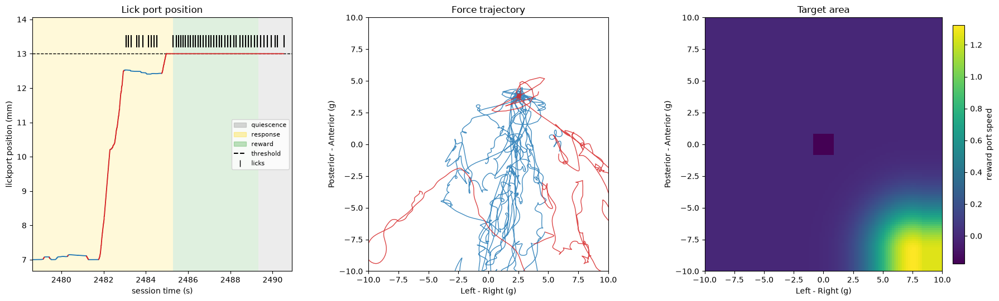

In [23]:
import pandas as pd

trial_of_interest_59 = 59
subject_id_59 = 'M029'
session_59 = 31
block_of_interest_59 = 3
t59_key = {'subject_id': subject_id_59, 'session': session_59, 'trial': trial_of_interest_59}
t60_key = {'subject_id': subject_id_59, 'session': session_59, 'trial': trial_of_interest_59 + 1}
b59_key = {'subject_id': subject_id_59, 'session': session_59, 'block': block_of_interest_59}
trial_uniform_range_59 = np.array([-1, 1, -1, 1]) * 10  # g

t59_start, t59_end = (experiment.SessionTrial() & t59_key).fetch1('trial_start_time', 'trial_end_time')
t59_start, t59_end = float(t59_start), float(t59_end)
t60_start = float((experiment.SessionTrial() & t60_key).fetch1('trial_start_time'))

go_time_59 = float((experiment.TrialEvent() & {**t59_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))
threshold_time_59 = float((experiment.TrialEvent() & {**t59_key, 'trial_event_type': 'threshold crossing'}).fetch1('trial_event_time'))
go60_time = float((experiment.TrialEvent() & {**t60_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))

abs_go59 = t59_start + go_time_59
abs_threshold59 = t59_start + threshold_time_59
abs_t59_end = t59_end  # == t60_start, no gap between trials
abs_go60 = t60_start + go60_time
window_start_59, window_end_59 = abs_go59, abs_go60  # show the whole response->reward->quiescence stretch

# --- lickport position: trial 59 response+reward, then trial 60 quiescence ---
lp59_time, lp59_val = (experiment.TrialRewardPortPosition() & t59_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp59_time = np.asarray(lp59_time, float)
lp59_val = np.asarray(lp59_val, float)

threshold_position_59 = lp59_val[np.clip(np.searchsorted(lp59_time, threshold_time_59, side='right') - 1, 0, len(lp59_val) - 1)]

extended59_mask = (lp59_time >= go_time_59) & (lp59_time <= (t59_end - t59_start))
t59_ext_abs = t59_start + lp59_time[extended59_mask]
v59_ext = lp59_val[extended59_mask]

lp60_time, lp60_val = (experiment.TrialRewardPortPosition() & t60_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp60_time = np.asarray(lp60_time, float)
lp60_val = np.asarray(lp60_val, float)
quiescence60_mask = (lp60_time >= 0) & (lp60_time <= go60_time)
t60_ext_abs = t60_start + lp60_time[quiescence60_mask]
v60_ext = lp60_val[quiescence60_mask]

lp_ext_df_59 = pd.concat([
    pd.DataFrame({'t': t59_ext_abs, 'v': v59_ext}),
    pd.DataFrame({'t': t60_ext_abs, 'v': v60_ext}),
]).groupby('t', as_index=False).last()
t_lp_ext_59, v_lp_ext_59 = lp_ext_df_59['t'].values, lp_ext_df_59['v'].values
is_step_ext_59 = classify_lickport_motion(t_lp_ext_59, v_lp_ext_59)  # shared by panels 1 and 2

# --- target area (reward port speed LUT): reused as-is from the trial-14 figure
#     (M029, session 25, block 2), per request, instead of trial 59's own block ---
target_key_reused = {'subject_id': 'M029', 'session': 25, 'block': 2}
task_setting_id_target, target_force_lut_reused = (experiment.TaskSettings() * experiment.Block() & target_key_reused).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target = bp._get_block_force_axes(
    experiment, 'M029', 25, task_setting_id_target)
lut_59, lut_extent_59, _, _ = bp._normalize_lut(
    target_force_lut_reused, force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target)
lut_disp_59 = bp._pad_lut_to_range(lut_59, lut_extent_59, trial_uniform_range_59)

# --- force trace (LR/PA), trial 59 + trial 60, gaussian-filtered (sigma=3ms) each -
#     uses trial 59's own block/session force-axis calibration ---
task_setting_id_59 = (experiment.TaskSettings() * experiment.Block() & b59_key).fetch1('task_setting_id')
force_axes_dict_59, lr_idx_59, pa_idx_59, lr_sign_59, pa_sign_59 = bp._get_block_force_axes(
    experiment, subject_id_59, session_59, task_setting_id_59)


def fetch_trial_lr_pa_59(trial_key, trial_start_abs):
    f0_time, f0_val = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                        & {**trial_key, 'force_axis_idx': 0}).fetch1('force_trace_time', 'force_trace_value')
    f1_val = (experiment.TrialForceTrace.TrialForceAxis() & {**trial_key, 'force_axis_idx': 1}).fetch1('force_trace_value')
    f0_time = np.asarray(f0_time, float)
    f0_val = np.asarray(f0_val, float) - np.median(f0_val)
    f1_val = np.asarray(f1_val, float) - np.median(f1_val)
    lr, pa = bp._lr_pa_traces([f0_val], [f1_val], lr_idx_59, pa_idx_59, lr_sign_59, pa_sign_59)
    lr, pa = lr[0], pa[0]
    sample_interval_s = bp._estimate_sample_interval([f0_time])
    sigma = bp.ms_to_samples_float(3.0, sample_interval_s, minimum=1e-6)
    (lr,), (pa,) = bp._filter_traces([lr], [pa], 'gaussian', sigma=sigma)
    return trial_start_abs + f0_time, lr, pa


f_time59, lr59, pa59 = fetch_trial_lr_pa_59(t59_key, t59_start)
f_time60, lr60, pa60 = fetch_trial_lr_pa_59(t60_key, t60_start)
f_time_all_59 = np.concatenate([f_time59, f_time60])
lr_all_59 = np.concatenate([lr59, lr60])
pa_all_59 = np.concatenate([pa59, pa60])

window_mask_59 = (f_time_all_59 >= window_start_59) & (f_time_all_59 <= window_end_59) & (f_time_all_59 < abs_threshold59)
f_time_59 = f_time_all_59[window_mask_59]
lr_smooth_59, pa_smooth_59 = lr_all_59[window_mask_59], pa_all_59[window_mask_59]

match_idx_59 = np.clip(np.searchsorted(t_lp_ext_59, f_time_59, side='right') - 1, 0, len(is_step_ext_59) - 1)
force_is_step_59 = is_step_ext_59[match_idx_59]

# --- plot ---
color_continuous = 'tab:blue'
color_step = 'tab:red'

fig, (ax_lp, ax_force, ax_target) = plt.subplots(1, 3, figsize=(18, 5.5))

ax_lp.axvspan(abs_go59, abs_threshold59, color='gold', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_threshold59, abs_t59_end, color='tab:green', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_t59_end, abs_go60, color='gray', alpha=0.15, linewidth=0)
ax_lp.axhline(threshold_position_59, color='black', linestyle='--', linewidth=1)

v_lp_continuous_59 = np.where(~is_step_ext_59, v_lp_ext_59, np.nan)
v_lp_step_59 = np.where(is_step_ext_59, v_lp_ext_59, np.nan)
ax_lp.step(t_lp_ext_59, v_lp_continuous_59, where='post', color=color_continuous, linewidth=1.3)
ax_lp.step(t_lp_ext_59, v_lp_step_59, where='post', color=color_step, linewidth=1.3)

lick_times59 = np.asarray((experiment.TrialEvent() & {**t59_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_times60 = np.asarray((experiment.TrialEvent() & {**t60_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_abs_59 = np.concatenate([t59_start + lick_times59, t60_start + lick_times60])
lick_abs_59 = lick_abs_59[(lick_abs_59 >= window_start_59) & (lick_abs_59 <= window_end_59)]
y0_59, y1_59 = v_lp_ext_59.min(), v_lp_ext_59.max()
tick_height_59 = 0.06 * (y1_59 - y0_59)
ax_lp.eventplot(lick_abs_59, orientation='horizontal', lineoffsets=y1_59 + tick_height_59, linelengths=tick_height_59, colors='black')

ax_lp.set_xlim(window_start_59, window_end_59)
ax_lp.set_xlabel('session time (s)')
ax_lp.set_ylabel('lickport position (mm)')
ax_lp.set_title('Lick port position')
ax_lp.legend(handles=[
    bp.Patch(color='gray', alpha=0.3, label='quiescence'),
    bp.Patch(color='gold', alpha=0.3, label='response'),
    bp.Patch(color='tab:green', alpha=0.3, label='reward'),
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=8, label='licks'),
], loc='center right', fontsize=8)

lr_continuous_59 = np.where(~force_is_step_59, lr_smooth_59, np.nan)
pa_continuous_59 = np.where(~force_is_step_59, pa_smooth_59, np.nan)
lr_step_59 = np.where(force_is_step_59, lr_smooth_59, np.nan)
pa_step_59 = np.where(force_is_step_59, pa_smooth_59, np.nan)
ax_force.plot(lr_continuous_59, pa_continuous_59, '-', color=color_continuous, linewidth=1, alpha=0.85)
ax_force.plot(lr_step_59, pa_step_59, '-', color=color_step, linewidth=1, alpha=0.85)
ax_force.set_xlim(trial_uniform_range_59[:2])
ax_force.set_ylim(trial_uniform_range_59[2:])
ax_force.set_xlabel('Left - Right (g)')
ax_force.set_ylabel('Posterior - Anterior (g)')
ax_force.set_title('Force trajectory')

im_target_59 = ax_target.imshow(lut_disp_59, extent=trial_uniform_range_59, origin='lower', cmap='viridis', aspect='auto')
ax_target.set_xlim(trial_uniform_range_59[:2])
ax_target.set_ylim(trial_uniform_range_59[2:])
ax_target.set_xlabel('Left - Right (g)')
ax_target.set_ylabel('Posterior - Anterior (g)')
ax_target.set_title('Target area')
fig.colorbar(im_target_59, ax=ax_target, label='reward port speed', fraction=0.046, pad=0.04)

plt.tight_layout(w_pad=3.5)

pos_59 = ax_force.get_position()
shift_59 = 0.02
ax_force.set_position([pos_59.x0, pos_59.y0, pos_59.width - shift_59, pos_59.height])

out_path = alt_dir / f'trial{trial_of_interest_59}_s{session_59}_lickport_vs_force_signature.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()


## Figure request: M029, day 31 (2026-09-14), trial 46

Same design again, now for trial 46 (block 3). This trial's response is extremely
long (~133.6 s), so this first pass shows the full stretch uncropped - likely to be
very dense given how much longer this is than anything seen so far (trial 48's ~28
s response was already the longest one shown). The target-area panel again reuses
the trial-14 figure's heatmap (M029, session 25, block 2).

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial46_s31_lickport_vs_force_signature.png

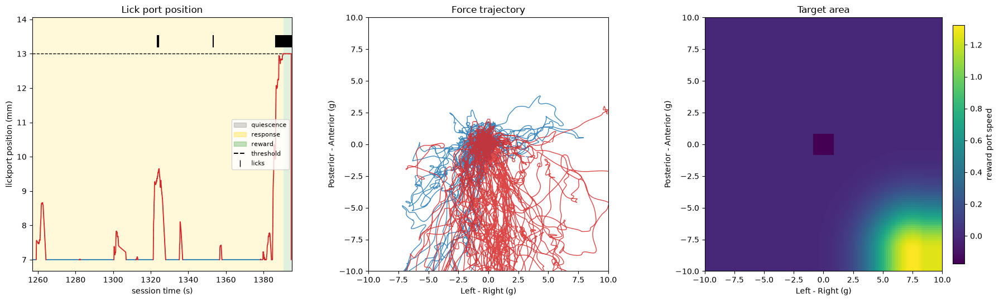

In [24]:
import pandas as pd

trial_of_interest_46 = 46
subject_id_46 = 'M029'
session_46 = 31
block_of_interest_46 = 3
t46_key = {'subject_id': subject_id_46, 'session': session_46, 'trial': trial_of_interest_46}
t47_key = {'subject_id': subject_id_46, 'session': session_46, 'trial': trial_of_interest_46 + 1}
b46_key = {'subject_id': subject_id_46, 'session': session_46, 'block': block_of_interest_46}
trial_uniform_range_46 = np.array([-1, 1, -1, 1]) * 10  # g

t46_start, t46_end = (experiment.SessionTrial() & t46_key).fetch1('trial_start_time', 'trial_end_time')
t46_start, t46_end = float(t46_start), float(t46_end)
t47_start = float((experiment.SessionTrial() & t47_key).fetch1('trial_start_time'))

go_time_46 = float((experiment.TrialEvent() & {**t46_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))
threshold_time_46 = float((experiment.TrialEvent() & {**t46_key, 'trial_event_type': 'threshold crossing'}).fetch1('trial_event_time'))
go47_time = float((experiment.TrialEvent() & {**t47_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))

abs_go46 = t46_start + go_time_46
abs_threshold46 = t46_start + threshold_time_46
abs_t46_end = t46_end  # == t47_start, no gap between trials
abs_go47 = t47_start + go47_time
window_start_46, window_end_46 = abs_go46, abs_go47  # show the whole response->reward->quiescence stretch

# --- lickport position: trial 46 response+reward, then trial 47 quiescence ---
lp46_time, lp46_val = (experiment.TrialRewardPortPosition() & t46_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp46_time = np.asarray(lp46_time, float)
lp46_val = np.asarray(lp46_val, float)

threshold_position_46 = lp46_val[np.clip(np.searchsorted(lp46_time, threshold_time_46, side='right') - 1, 0, len(lp46_val) - 1)]

extended46_mask = (lp46_time >= go_time_46) & (lp46_time <= (t46_end - t46_start))
t46_ext_abs = t46_start + lp46_time[extended46_mask]
v46_ext = lp46_val[extended46_mask]

lp47_time, lp47_val = (experiment.TrialRewardPortPosition() & t47_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp47_time = np.asarray(lp47_time, float)
lp47_val = np.asarray(lp47_val, float)
quiescence47_mask = (lp47_time >= 0) & (lp47_time <= go47_time)
t47_ext_abs = t47_start + lp47_time[quiescence47_mask]
v47_ext = lp47_val[quiescence47_mask]

lp_ext_df_46 = pd.concat([
    pd.DataFrame({'t': t46_ext_abs, 'v': v46_ext}),
    pd.DataFrame({'t': t47_ext_abs, 'v': v47_ext}),
]).groupby('t', as_index=False).last()
t_lp_ext_46, v_lp_ext_46 = lp_ext_df_46['t'].values, lp_ext_df_46['v'].values
is_step_ext_46 = classify_lickport_motion(t_lp_ext_46, v_lp_ext_46)  # shared by panels 1 and 2

# --- target area (reward port speed LUT): reused as-is from the trial-14 figure
#     (M029, session 25, block 2), per request, instead of trial 46's own block ---
target_key_reused = {'subject_id': 'M029', 'session': 25, 'block': 2}
task_setting_id_target, target_force_lut_reused = (experiment.TaskSettings() * experiment.Block() & target_key_reused).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target = bp._get_block_force_axes(
    experiment, 'M029', 25, task_setting_id_target)
lut_46, lut_extent_46, _, _ = bp._normalize_lut(
    target_force_lut_reused, force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target)
lut_disp_46 = bp._pad_lut_to_range(lut_46, lut_extent_46, trial_uniform_range_46)

# --- force trace (LR/PA), trial 46 + trial 47, gaussian-filtered (sigma=3ms) each -
#     uses trial 46's own block/session force-axis calibration ---
task_setting_id_46 = (experiment.TaskSettings() * experiment.Block() & b46_key).fetch1('task_setting_id')
force_axes_dict_46, lr_idx_46, pa_idx_46, lr_sign_46, pa_sign_46 = bp._get_block_force_axes(
    experiment, subject_id_46, session_46, task_setting_id_46)


def fetch_trial_lr_pa_46(trial_key, trial_start_abs):
    f0_time, f0_val = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                        & {**trial_key, 'force_axis_idx': 0}).fetch1('force_trace_time', 'force_trace_value')
    f1_val = (experiment.TrialForceTrace.TrialForceAxis() & {**trial_key, 'force_axis_idx': 1}).fetch1('force_trace_value')
    f0_time = np.asarray(f0_time, float)
    f0_val = np.asarray(f0_val, float) - np.median(f0_val)
    f1_val = np.asarray(f1_val, float) - np.median(f1_val)
    lr, pa = bp._lr_pa_traces([f0_val], [f1_val], lr_idx_46, pa_idx_46, lr_sign_46, pa_sign_46)
    lr, pa = lr[0], pa[0]
    sample_interval_s = bp._estimate_sample_interval([f0_time])
    sigma = bp.ms_to_samples_float(3.0, sample_interval_s, minimum=1e-6)
    (lr,), (pa,) = bp._filter_traces([lr], [pa], 'gaussian', sigma=sigma)
    return trial_start_abs + f0_time, lr, pa


f_time46, lr46, pa46 = fetch_trial_lr_pa_46(t46_key, t46_start)
f_time47, lr47, pa47 = fetch_trial_lr_pa_46(t47_key, t47_start)
f_time_all_46 = np.concatenate([f_time46, f_time47])
lr_all_46 = np.concatenate([lr46, lr47])
pa_all_46 = np.concatenate([pa46, pa47])

window_mask_46 = (f_time_all_46 >= window_start_46) & (f_time_all_46 <= window_end_46) & (f_time_all_46 < abs_threshold46)
f_time_46 = f_time_all_46[window_mask_46]
lr_smooth_46, pa_smooth_46 = lr_all_46[window_mask_46], pa_all_46[window_mask_46]

match_idx_46 = np.clip(np.searchsorted(t_lp_ext_46, f_time_46, side='right') - 1, 0, len(is_step_ext_46) - 1)
force_is_step_46 = is_step_ext_46[match_idx_46]

# --- plot ---
color_continuous = 'tab:blue'
color_step = 'tab:red'

fig, (ax_lp, ax_force, ax_target) = plt.subplots(1, 3, figsize=(18, 5.5))

ax_lp.axvspan(abs_go46, abs_threshold46, color='gold', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_threshold46, abs_t46_end, color='tab:green', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_t46_end, abs_go47, color='gray', alpha=0.15, linewidth=0)
ax_lp.axhline(threshold_position_46, color='black', linestyle='--', linewidth=1)

v_lp_continuous_46 = np.where(~is_step_ext_46, v_lp_ext_46, np.nan)
v_lp_step_46 = np.where(is_step_ext_46, v_lp_ext_46, np.nan)
ax_lp.step(t_lp_ext_46, v_lp_continuous_46, where='post', color=color_continuous, linewidth=1.3)
ax_lp.step(t_lp_ext_46, v_lp_step_46, where='post', color=color_step, linewidth=1.3)

lick_times46 = np.asarray((experiment.TrialEvent() & {**t46_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_times47 = np.asarray((experiment.TrialEvent() & {**t47_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_abs_46 = np.concatenate([t46_start + lick_times46, t47_start + lick_times47])
lick_abs_46 = lick_abs_46[(lick_abs_46 >= window_start_46) & (lick_abs_46 <= window_end_46)]
y0_46, y1_46 = v_lp_ext_46.min(), v_lp_ext_46.max()
tick_height_46 = 0.06 * (y1_46 - y0_46)
ax_lp.eventplot(lick_abs_46, orientation='horizontal', lineoffsets=y1_46 + tick_height_46, linelengths=tick_height_46, colors='black')

ax_lp.set_xlim(window_start_46, window_end_46)
ax_lp.set_xlabel('session time (s)')
ax_lp.set_ylabel('lickport position (mm)')
ax_lp.set_title('Lick port position')
ax_lp.legend(handles=[
    bp.Patch(color='gray', alpha=0.3, label='quiescence'),
    bp.Patch(color='gold', alpha=0.3, label='response'),
    bp.Patch(color='tab:green', alpha=0.3, label='reward'),
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=8, label='licks'),
], loc='center right', fontsize=8)

lr_continuous_46 = np.where(~force_is_step_46, lr_smooth_46, np.nan)
pa_continuous_46 = np.where(~force_is_step_46, pa_smooth_46, np.nan)
lr_step_46 = np.where(force_is_step_46, lr_smooth_46, np.nan)
pa_step_46 = np.where(force_is_step_46, pa_smooth_46, np.nan)
ax_force.plot(lr_continuous_46, pa_continuous_46, '-', color=color_continuous, linewidth=1, alpha=0.85)
ax_force.plot(lr_step_46, pa_step_46, '-', color=color_step, linewidth=1, alpha=0.85)
ax_force.set_xlim(trial_uniform_range_46[:2])
ax_force.set_ylim(trial_uniform_range_46[2:])
ax_force.set_xlabel('Left - Right (g)')
ax_force.set_ylabel('Posterior - Anterior (g)')
ax_force.set_title('Force trajectory')

im_target_46 = ax_target.imshow(lut_disp_46, extent=trial_uniform_range_46, origin='lower', cmap='viridis', aspect='auto')
ax_target.set_xlim(trial_uniform_range_46[:2])
ax_target.set_ylim(trial_uniform_range_46[2:])
ax_target.set_xlabel('Left - Right (g)')
ax_target.set_ylabel('Posterior - Anterior (g)')
ax_target.set_title('Target area')
fig.colorbar(im_target_46, ax=ax_target, label='reward port speed', fraction=0.046, pad=0.04)

plt.tight_layout(w_pad=3.5)

pos_46 = ax_force.get_position()
shift_46 = 0.02
ax_force.set_position([pos_46.x0, pos_46.y0, pos_46.width - shift_46, pos_46.height])

out_path = alt_dir / f'trial{trial_of_interest_46}_s{session_46}_lickport_vs_force_signature.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()


## Figure request: M029, day 31 (2026-09-14), trial 16 - a gradual, non-jumpy trial

Looking for a trial with a slow, gradual lickport rise instead of a steep jump: scanned
every trial in this session with a 5-20 s response duration and ranked them by how
uniform the movement velocity was (peak velocity / mean velocity - lower means no
single sharp burst dominates) and how little time was spent holding still (low
"flat" fraction). Trial 16 (block 1) came out on top: a 5.45 s response spent mostly
in continuous motion, with the smallest peak-to-mean velocity ratio among candidates
in that duration range. Same design as before; the target-area panel again reuses
the trial-14 figure's heatmap (M029, session 25, block 2).

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial16_s31_lickport_vs_force_signature.png

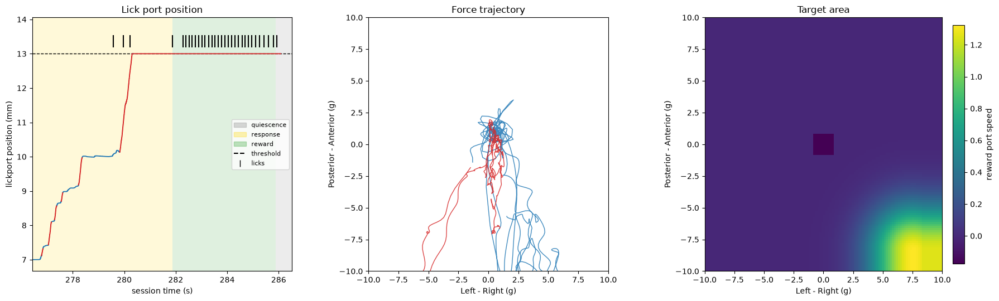

In [25]:
import pandas as pd

trial_of_interest_16 = 16
subject_id_16 = 'M029'
session_16 = 31
block_of_interest_16 = 1
t16_key = {'subject_id': subject_id_16, 'session': session_16, 'trial': trial_of_interest_16}
t17_key = {'subject_id': subject_id_16, 'session': session_16, 'trial': trial_of_interest_16 + 1}
b16_key = {'subject_id': subject_id_16, 'session': session_16, 'block': block_of_interest_16}
trial_uniform_range_16 = np.array([-1, 1, -1, 1]) * 10  # g

t16_start, t16_end = (experiment.SessionTrial() & t16_key).fetch1('trial_start_time', 'trial_end_time')
t16_start, t16_end = float(t16_start), float(t16_end)
t17_start = float((experiment.SessionTrial() & t17_key).fetch1('trial_start_time'))

go_time_16 = float((experiment.TrialEvent() & {**t16_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))
threshold_time_16 = float((experiment.TrialEvent() & {**t16_key, 'trial_event_type': 'threshold crossing'}).fetch1('trial_event_time'))
go17_time = float((experiment.TrialEvent() & {**t17_key, 'trial_event_type': 'go'}).fetch1('trial_event_time'))

abs_go16 = t16_start + go_time_16
abs_threshold16 = t16_start + threshold_time_16
abs_t16_end = t16_end  # == t17_start, no gap between trials
abs_go17 = t17_start + go17_time
window_start_16, window_end_16 = abs_go16, abs_go17  # show the whole response->reward->quiescence stretch

# --- lickport position: trial 16 response+reward, then trial 17 quiescence ---
lp16_time, lp16_val = (experiment.TrialRewardPortPosition() & t16_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp16_time = np.asarray(lp16_time, float)
lp16_val = np.asarray(lp16_val, float)

threshold_position_16 = lp16_val[np.clip(np.searchsorted(lp16_time, threshold_time_16, side='right') - 1, 0, len(lp16_val) - 1)]

extended16_mask = (lp16_time >= go_time_16) & (lp16_time <= (t16_end - t16_start))
t16_ext_abs = t16_start + lp16_time[extended16_mask]
v16_ext = lp16_val[extended16_mask]

lp17_time, lp17_val = (experiment.TrialRewardPortPosition() & t17_key).fetch1(
    'reward_port_position_time', 'reward_port_position_values')
lp17_time = np.asarray(lp17_time, float)
lp17_val = np.asarray(lp17_val, float)
quiescence17_mask = (lp17_time >= 0) & (lp17_time <= go17_time)
t17_ext_abs = t17_start + lp17_time[quiescence17_mask]
v17_ext = lp17_val[quiescence17_mask]

lp_ext_df_16 = pd.concat([
    pd.DataFrame({'t': t16_ext_abs, 'v': v16_ext}),
    pd.DataFrame({'t': t17_ext_abs, 'v': v17_ext}),
]).groupby('t', as_index=False).last()
t_lp_ext_16, v_lp_ext_16 = lp_ext_df_16['t'].values, lp_ext_df_16['v'].values
is_step_ext_16 = classify_lickport_motion(t_lp_ext_16, v_lp_ext_16)  # shared by panels 1 and 2

# --- target area (reward port speed LUT): reused as-is from the trial-14 figure
#     (M029, session 25, block 2), per request, instead of trial 16's own block ---
target_key_reused = {'subject_id': 'M029', 'session': 25, 'block': 2}
task_setting_id_target, target_force_lut_reused = (experiment.TaskSettings() * experiment.Block() & target_key_reused).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target = bp._get_block_force_axes(
    experiment, 'M029', 25, task_setting_id_target)
lut_16, lut_extent_16, _, _ = bp._normalize_lut(
    target_force_lut_reused, force_axes_dict_target, lr_idx_target, pa_idx_target, lr_sign_target, pa_sign_target)
lut_disp_16 = bp._pad_lut_to_range(lut_16, lut_extent_16, trial_uniform_range_16)

# --- force trace (LR/PA), trial 16 + trial 17, gaussian-filtered (sigma=3ms) each -
#     uses trial 16's own block/session force-axis calibration ---
task_setting_id_16 = (experiment.TaskSettings() * experiment.Block() & b16_key).fetch1('task_setting_id')
force_axes_dict_16, lr_idx_16, pa_idx_16, lr_sign_16, pa_sign_16 = bp._get_block_force_axes(
    experiment, subject_id_16, session_16, task_setting_id_16)


def fetch_trial_lr_pa_16(trial_key, trial_start_abs):
    f0_time, f0_val = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                        & {**trial_key, 'force_axis_idx': 0}).fetch1('force_trace_time', 'force_trace_value')
    f1_val = (experiment.TrialForceTrace.TrialForceAxis() & {**trial_key, 'force_axis_idx': 1}).fetch1('force_trace_value')
    f0_time = np.asarray(f0_time, float)
    f0_val = np.asarray(f0_val, float) - np.median(f0_val)
    f1_val = np.asarray(f1_val, float) - np.median(f1_val)
    lr, pa = bp._lr_pa_traces([f0_val], [f1_val], lr_idx_16, pa_idx_16, lr_sign_16, pa_sign_16)
    lr, pa = lr[0], pa[0]
    sample_interval_s = bp._estimate_sample_interval([f0_time])
    sigma = bp.ms_to_samples_float(3.0, sample_interval_s, minimum=1e-6)
    (lr,), (pa,) = bp._filter_traces([lr], [pa], 'gaussian', sigma=sigma)
    return trial_start_abs + f0_time, lr, pa


f_time16, lr16, pa16 = fetch_trial_lr_pa_16(t16_key, t16_start)
f_time17, lr17, pa17 = fetch_trial_lr_pa_16(t17_key, t17_start)
f_time_all_16 = np.concatenate([f_time16, f_time17])
lr_all_16 = np.concatenate([lr16, lr17])
pa_all_16 = np.concatenate([pa16, pa17])

window_mask_16 = (f_time_all_16 >= window_start_16) & (f_time_all_16 <= window_end_16) & (f_time_all_16 < abs_threshold16)
f_time_16 = f_time_all_16[window_mask_16]
lr_smooth_16, pa_smooth_16 = lr_all_16[window_mask_16], pa_all_16[window_mask_16]

match_idx_16 = np.clip(np.searchsorted(t_lp_ext_16, f_time_16, side='right') - 1, 0, len(is_step_ext_16) - 1)
force_is_step_16 = is_step_ext_16[match_idx_16]

# --- plot ---
color_continuous = 'tab:blue'
color_step = 'tab:red'

fig, (ax_lp, ax_force, ax_target) = plt.subplots(1, 3, figsize=(18, 5.5))

ax_lp.axvspan(abs_go16, abs_threshold16, color='gold', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_threshold16, abs_t16_end, color='tab:green', alpha=0.15, linewidth=0)
ax_lp.axvspan(abs_t16_end, abs_go17, color='gray', alpha=0.15, linewidth=0)
ax_lp.axhline(threshold_position_16, color='black', linestyle='--', linewidth=1)

v_lp_continuous_16 = np.where(~is_step_ext_16, v_lp_ext_16, np.nan)
v_lp_step_16 = np.where(is_step_ext_16, v_lp_ext_16, np.nan)
ax_lp.step(t_lp_ext_16, v_lp_continuous_16, where='post', color=color_continuous, linewidth=1.3)
ax_lp.step(t_lp_ext_16, v_lp_step_16, where='post', color=color_step, linewidth=1.3)

lick_times16 = np.asarray((experiment.TrialEvent() & {**t16_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_times17 = np.asarray((experiment.TrialEvent() & {**t17_key, 'trial_event_type': 'lick'}).fetch('trial_event_time'), float)
lick_abs_16 = np.concatenate([t16_start + lick_times16, t17_start + lick_times17])
lick_abs_16 = lick_abs_16[(lick_abs_16 >= window_start_16) & (lick_abs_16 <= window_end_16)]
y0_16, y1_16 = v_lp_ext_16.min(), v_lp_ext_16.max()
tick_height_16 = 0.06 * (y1_16 - y0_16)
ax_lp.eventplot(lick_abs_16, orientation='horizontal', lineoffsets=y1_16 + tick_height_16, linelengths=tick_height_16, colors='black')

ax_lp.set_xlim(window_start_16, window_end_16)
ax_lp.set_xlabel('session time (s)')
ax_lp.set_ylabel('lickport position (mm)')
ax_lp.set_title('Lick port position')
ax_lp.legend(handles=[
    bp.Patch(color='gray', alpha=0.3, label='quiescence'),
    bp.Patch(color='gold', alpha=0.3, label='response'),
    bp.Patch(color='tab:green', alpha=0.3, label='reward'),
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=8, label='licks'),
], loc='center right', fontsize=8)

lr_continuous_16 = np.where(~force_is_step_16, lr_smooth_16, np.nan)
pa_continuous_16 = np.where(~force_is_step_16, pa_smooth_16, np.nan)
lr_step_16 = np.where(force_is_step_16, lr_smooth_16, np.nan)
pa_step_16 = np.where(force_is_step_16, pa_smooth_16, np.nan)
ax_force.plot(lr_continuous_16, pa_continuous_16, '-', color=color_continuous, linewidth=1, alpha=0.85)
ax_force.plot(lr_step_16, pa_step_16, '-', color=color_step, linewidth=1, alpha=0.85)
ax_force.set_xlim(trial_uniform_range_16[:2])
ax_force.set_ylim(trial_uniform_range_16[2:])
ax_force.set_xlabel('Left - Right (g)')
ax_force.set_ylabel('Posterior - Anterior (g)')
ax_force.set_title('Force trajectory')

im_target_16 = ax_target.imshow(lut_disp_16, extent=trial_uniform_range_16, origin='lower', cmap='viridis', aspect='auto')
ax_target.set_xlim(trial_uniform_range_16[:2])
ax_target.set_ylim(trial_uniform_range_16[2:])
ax_target.set_xlabel('Left - Right (g)')
ax_target.set_ylabel('Posterior - Anterior (g)')
ax_target.set_title('Target area')
fig.colorbar(im_target_16, ax=ax_target, label='reward port speed', fraction=0.046, pad=0.04)

plt.tight_layout(w_pad=3.5)

pos_16 = ax_force.get_position()
shift_16 = 0.02
ax_force.set_position([pos_16.x0, pos_16.y0, pos_16.width - shift_16, pos_16.height])

out_path = alt_dir / f'trial{trial_of_interest_16}_s{session_16}_lickport_vs_force_signature.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()


## Trial 14: force trajectory overlaid on target area

Same underlying data as `trial14_lickport_vs_force_signature`, but panels 2 and 3
are merged into one: the force trajectory is drawn directly on top of the target-
area heatmap instead of side by side. Since the heatmap's background is mostly dark
(viridis), the trajectory is drawn in plain black (the continuous vs. step-like
color distinction is dropped for this version) so it stays visible against it.

Two versions are saved - one with the normal line width, one a bit thicker - and
both use larger text throughout (28pt for axis labels/legend, 36pt for titles),
since this is meant for a poster/large-format use.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial14_lickport_vs_force_overlay.png

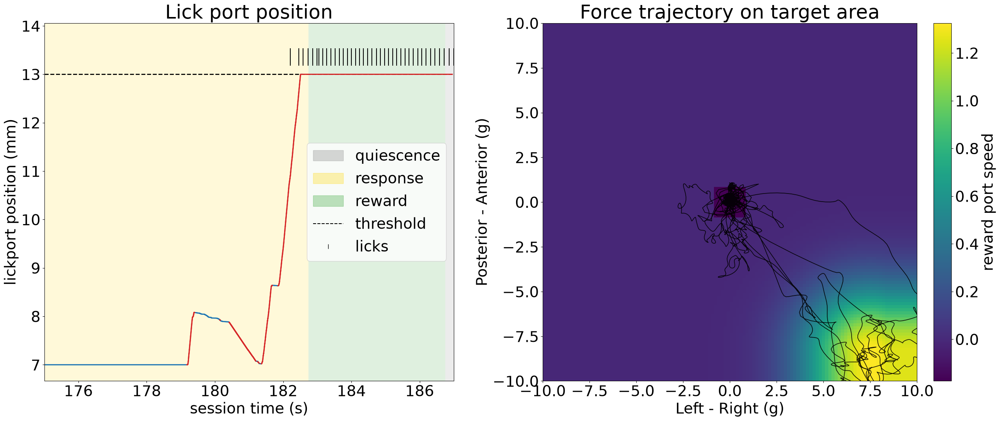

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial14_lickport_vs_force_overlay_thick.png

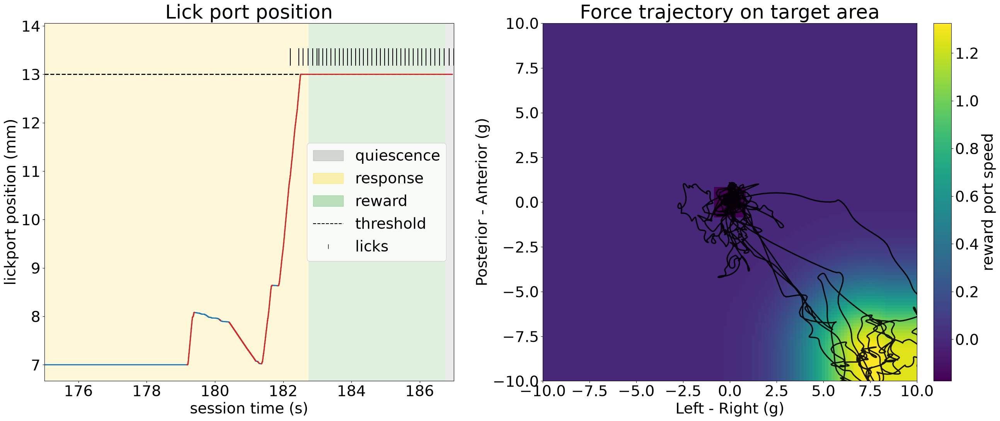

In [26]:
FONT_LABEL = 28
FONT_TITLE = 36

# recompute the target LUT locally (bare names like lut_disp/lut/force_axes_dict get
# reassigned by several other cells further down the notebook, so relying on them
# here would silently pick up a different block's target)
task_setting_id_ov, target_force_lut_ov = (experiment.TaskSettings() * experiment.Block() & b2_key).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_ov, lr_idx_ov, pa_idx_ov, lr_sign_ov, pa_sign_ov = bp._get_block_force_axes(
    experiment, subject_id, session, task_setting_id_ov)
lut_ov, lut_extent_ov, _, _ = bp._normalize_lut(
    target_force_lut_ov, force_axes_dict_ov, lr_idx_ov, pa_idx_ov, lr_sign_ov, pa_sign_ov)
lut_disp_ov = bp._pad_lut_to_range(lut_ov, lut_extent_ov, trial_uniform_range)

for trajectory_linewidth, suffix in [(1.2, ''), (2.5, '_thick')]:
    fig, (ax_lp, ax_overlay) = plt.subplots(1, 2, figsize=(26, 11))

    ax_lp.axvspan(abs_go14, abs_threshold14, color='gold', alpha=0.15, linewidth=0)
    ax_lp.axvspan(abs_threshold14, abs_t14_end, color='tab:green', alpha=0.15, linewidth=0)
    ax_lp.axvspan(abs_t14_end, abs_go15, color='gray', alpha=0.15, linewidth=0)
    ax_lp.axhline(threshold_position, color='black', linestyle='--', linewidth=2)

    v_lp_continuous = np.where(~is_step_ext, v_lp_ext, np.nan)
    v_lp_step = np.where(is_step_ext, v_lp_ext, np.nan)
    ax_lp.step(t_lp_ext, v_lp_continuous, where='post', color=color_continuous, linewidth=2.2)
    ax_lp.step(t_lp_ext, v_lp_step, where='post', color=color_step, linewidth=2.2)

    y0, y1 = v_lp_ext.min(), v_lp_ext.max()
    tick_height = 0.06 * (y1 - y0)
    ax_lp.eventplot(lick_abs, orientation='horizontal', lineoffsets=y1 + tick_height, linelengths=tick_height, colors='black')

    ax_lp.set_xlim(window_start, window_end)
    ax_lp.set_xlabel('session time (s)', fontsize=FONT_LABEL)
    ax_lp.set_ylabel('lickport position (mm)', fontsize=FONT_LABEL)
    ax_lp.set_title('Lick port position', fontsize=FONT_TITLE)
    ax_lp.tick_params(labelsize=FONT_LABEL)
    ax_lp.legend(handles=[
        bp.Patch(color='gray', alpha=0.3, label='quiescence'),
        bp.Patch(color='gold', alpha=0.3, label='response'),
        bp.Patch(color='tab:green', alpha=0.3, label='reward'),
        Line2D([0], [0], color='black', linestyle='--', label='threshold'),
        Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=8, label='licks'),
    ], loc='center right', fontsize=FONT_LABEL)

    im_target = ax_overlay.imshow(lut_disp_ov, extent=trial_uniform_range, origin='lower', cmap='viridis', aspect='auto')
    ax_overlay.plot(lr_smooth, pa_smooth, '-', color='black', linewidth=trajectory_linewidth, alpha=0.9)
    ax_overlay.set_xlim(trial_uniform_range[:2])
    ax_overlay.set_ylim(trial_uniform_range[2:])
    ax_overlay.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
    ax_overlay.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
    ax_overlay.set_title('Force trajectory on target area', fontsize=FONT_TITLE)
    ax_overlay.tick_params(labelsize=FONT_LABEL)
    cbar = fig.colorbar(im_target, ax=ax_overlay, fraction=0.046, pad=0.04)
    cbar.set_label('reward port speed', fontsize=FONT_LABEL)
    cbar.ax.tick_params(labelsize=FONT_LABEL)

    plt.tight_layout(w_pad=4.0)

    out_path = alt_dir / f'trial14_lickport_vs_force_overlay{suffix}.png'
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print('Saved to', out_path)
    plt.show()

## Trial 14: force trajectory on target area, poster-scale text

Same merged panel-2/3 design as the overlay figure above, but sized for a large
scientific poster (90 x 120 cm): much larger text (44pt axis labels/legend, 56pt
titles - see the printed values in the cell output), a trajectory line width of
2.5, and a legend entry identifying the trajectory line. Two color variants are
saved - black trajectory and white trajectory - since which reads better will
depend on the poster's surrounding color scheme.

Using FONT_LABEL=44, FONT_TITLE=56, FONT_LEGEND=34, linewidth=2.5

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial14_lickport_vs_force_overlay_poster_black.png

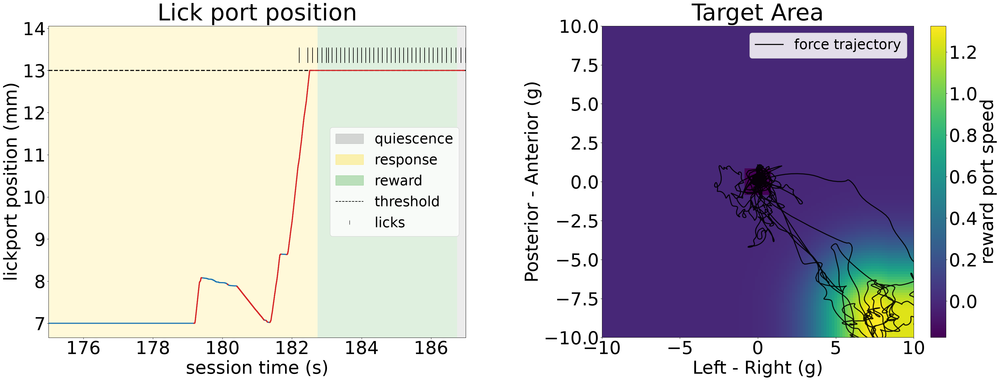

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial14_lickport_vs_force_overlay_poster_white.png

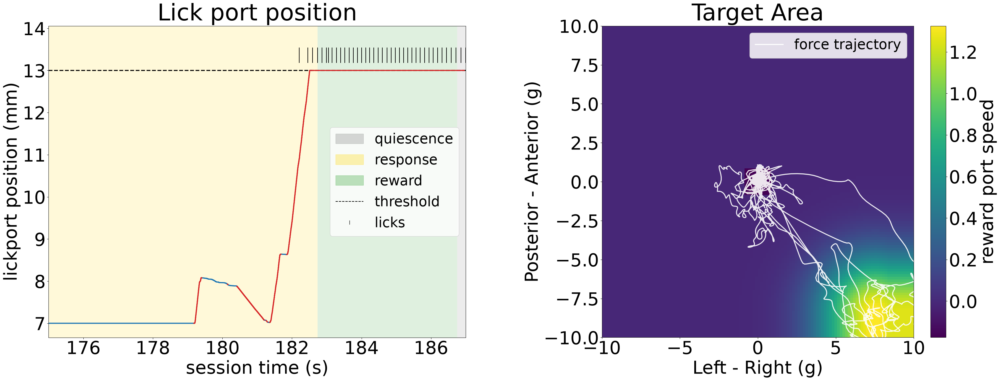

In [27]:
FONT_LABEL = 44
FONT_TITLE = 56
FONT_LEGEND = 34  # shared by both panels' legends (between the old 24 and 44)
TRAJECTORY_LINEWIDTH = 2.5
print(f'Using FONT_LABEL={FONT_LABEL}, FONT_TITLE={FONT_TITLE}, FONT_LEGEND={FONT_LEGEND}, linewidth={TRAJECTORY_LINEWIDTH}')

# recompute the target LUT locally (bare names like lut_disp/lut/force_axes_dict get
# reassigned by several other cells further down the notebook, so relying on them
# here would silently pick up a different block's target)
task_setting_id_ov, target_force_lut_ov = (experiment.TaskSettings() * experiment.Block() & b2_key).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_ov, lr_idx_ov, pa_idx_ov, lr_sign_ov, pa_sign_ov = bp._get_block_force_axes(
    experiment, subject_id, session, task_setting_id_ov)
lut_ov, lut_extent_ov, _, _ = bp._normalize_lut(
    target_force_lut_ov, force_axes_dict_ov, lr_idx_ov, pa_idx_ov, lr_sign_ov, pa_sign_ov)
lut_disp_ov = bp._pad_lut_to_range(lut_ov, lut_extent_ov, trial_uniform_range)

for trajectory_color, suffix in [('black', '_black'), ('white', '_white')]:
    fig, (ax_lp, ax_overlay) = plt.subplots(1, 2, figsize=(34, 13))

    ax_lp.axvspan(abs_go14, abs_threshold14, color='gold', alpha=0.15, linewidth=0)
    ax_lp.axvspan(abs_threshold14, abs_t14_end, color='tab:green', alpha=0.15, linewidth=0)
    ax_lp.axvspan(abs_t14_end, abs_go15, color='gray', alpha=0.15, linewidth=0)
    ax_lp.axhline(threshold_position, color='black', linestyle='--', linewidth=2.5)

    v_lp_continuous = np.where(~is_step_ext, v_lp_ext, np.nan)
    v_lp_step = np.where(is_step_ext, v_lp_ext, np.nan)
    ax_lp.step(t_lp_ext, v_lp_continuous, where='post', color=color_continuous, linewidth=2.8)
    ax_lp.step(t_lp_ext, v_lp_step, where='post', color=color_step, linewidth=2.8)

    y0, y1 = v_lp_ext.min(), v_lp_ext.max()
    tick_height = 0.06 * (y1 - y0)
    ax_lp.eventplot(lick_abs, orientation='horizontal', lineoffsets=y1 + tick_height, linelengths=tick_height, colors='black')

    ax_lp.set_xlim(window_start, window_end)
    ax_lp.set_xlabel('session time (s)', fontsize=FONT_LABEL)
    ax_lp.set_ylabel('lickport position (mm)', fontsize=FONT_LABEL)
    ax_lp.set_title('Lick port position', fontsize=FONT_TITLE)
    ax_lp.tick_params(labelsize=FONT_LABEL)
    ax_lp.legend(handles=[
        bp.Patch(color='gray', alpha=0.3, label='quiescence'),
        bp.Patch(color='gold', alpha=0.3, label='response'),
        bp.Patch(color='tab:green', alpha=0.3, label='reward'),
        Line2D([0], [0], color='black', linestyle='--', label='threshold'),
        Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=10, label='licks'),
    ], loc='center right', fontsize=FONT_LEGEND)

    im_target = ax_overlay.imshow(lut_disp_ov, extent=trial_uniform_range, origin='lower', cmap='viridis', aspect='equal')
    ax_overlay.plot(lr_smooth, pa_smooth, '-', color=trajectory_color, linewidth=TRAJECTORY_LINEWIDTH, alpha=0.9)
    ax_overlay.set_xlim(trial_uniform_range[:2])
    ax_overlay.set_ylim(trial_uniform_range[2:])
    ax_overlay.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
    ax_overlay.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
    ax_overlay.set_title('Target Area', fontsize=FONT_TITLE)
    ax_overlay.tick_params(labelsize=FONT_LABEL)
    ax_overlay.legend(handles=[
        Line2D([0], [0], color=trajectory_color, linewidth=TRAJECTORY_LINEWIDTH, label='force trajectory'),
    ], loc='upper right', fontsize=FONT_LEGEND, facecolor='white', framealpha=0.85)
    cbar = fig.colorbar(im_target, ax=ax_overlay, fraction=0.046, pad=0.04)
    cbar.set_label('reward port speed', fontsize=FONT_LABEL)
    cbar.ax.tick_params(labelsize=FONT_LABEL)

    plt.tight_layout(w_pad=4.0)

    out_path = alt_dir / f'trial14_lickport_vs_force_overlay_poster{suffix}.png'
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print('Saved to', out_path)
    plt.show()

## Poster-scale redo: 20g combined figures (hand-picked and first/last trials)

Both 20g combined figures redone with the same text sizes as
`trial14_lickport_vs_force_overlay_poster_black` (44pt axis labels, 56pt block
headers, 48pt row-2 panel titles). Each "Time to Reward" panel now shows a faint
dashed exponential-decay fit (instead of a straight first-to-last line) as the
block's learning trend. Dots are slightly larger, force-trajectory lines are 2.5pt,
and both colorbars (reward port speed; trial first/last) have been removed.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_target_reward_trajectories_colored_20g_poster.png

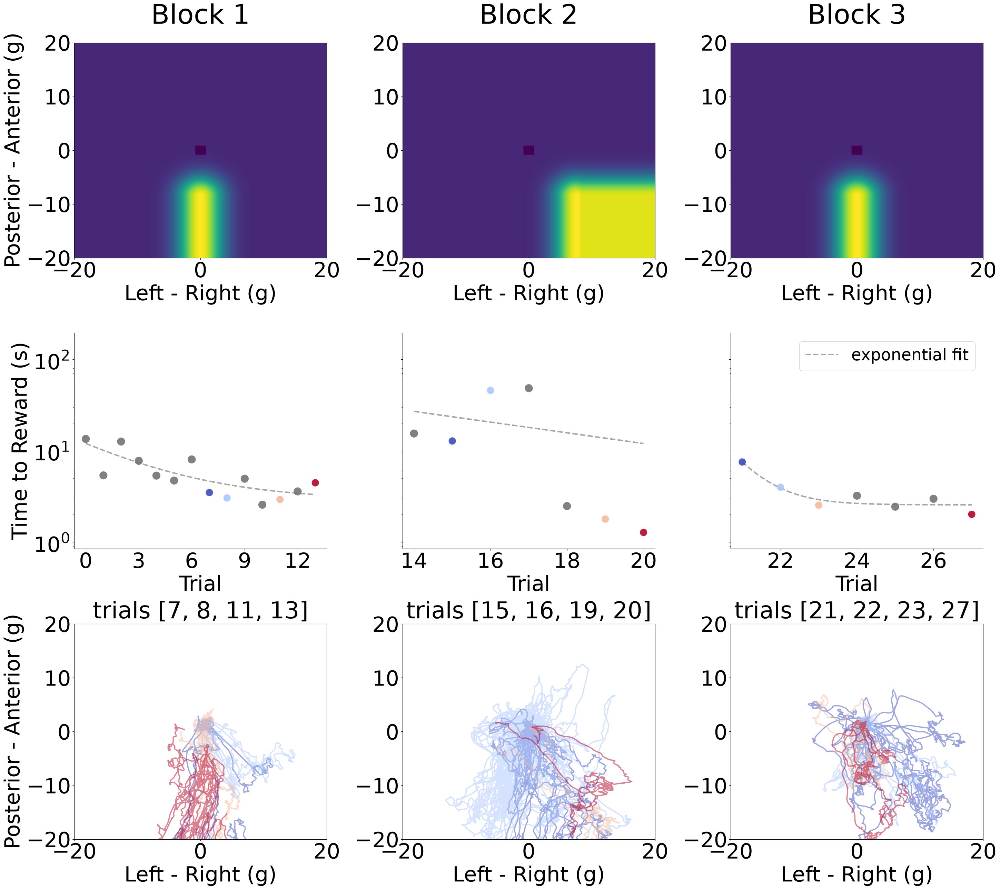

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_target_reward_trajectories_colored_20g_firstlast_poster.png

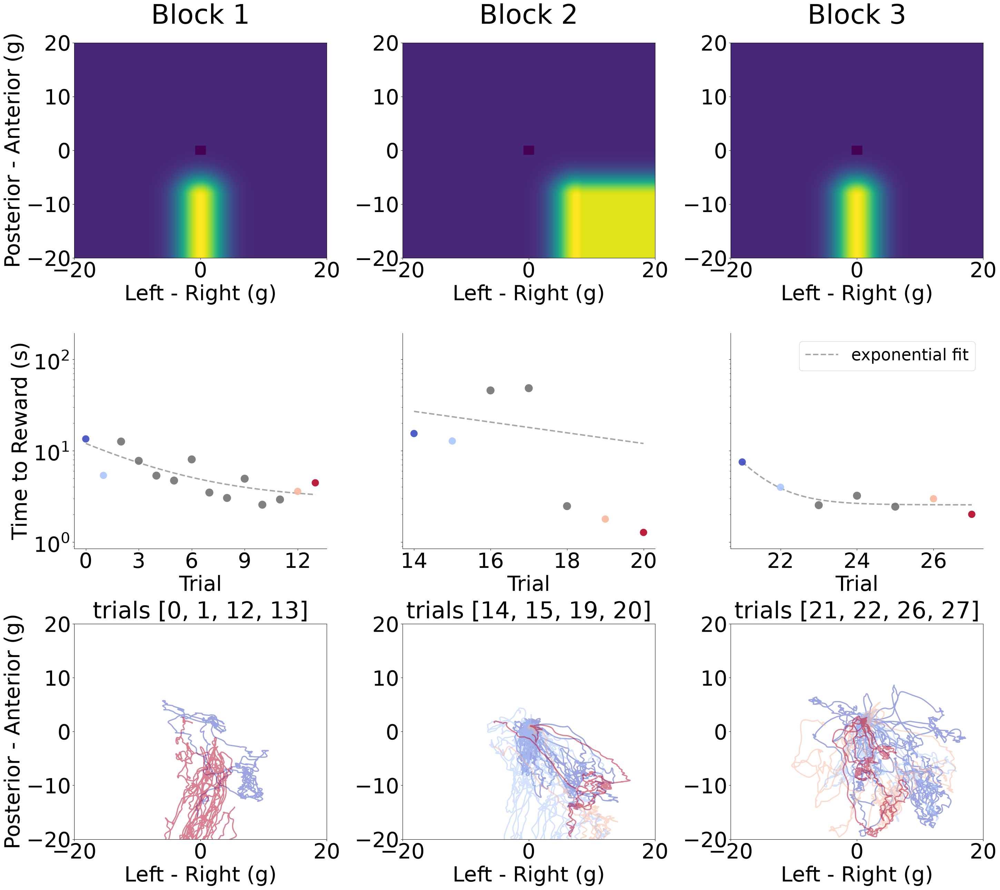

In [28]:
from scipy.optimize import curve_fit

FONT_LABEL = 44
FONT_TITLE = 56
FONT_TRIAL_TITLE = 48  # smaller than the big block headers, for the row-2 'trials [...]' titles
FONT_LEGEND = 34


def exp_decay(x, a, tau, c):
    return c + a * np.exp(-x / tau)


def fit_exponential_trend(trials, response_value):
    x = trials - trials.min()
    p0 = [max(response_value.max() - response_value.min(), 1e-3), max(len(x) / 3, 1.0), max(response_value.min(), 1e-3)]
    try:
        popt, _ = curve_fit(exp_decay, x, response_value, p0=p0, maxfev=10000,
                             bounds=([0, 1e-3, 0], [np.inf, np.inf, np.inf]))
        return popt
    except RuntimeError:
        return None


def build_20g_combined_figure(trials_by_block_dict, out_name):
    fig = plt.figure(figsize=(34, 30))
    gs = plt.GridSpec(3, 3, figure=fig, width_ratios=[1, 1, 1],
                       height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)

    selected_by_label = {labels_by_block[b]: t for b, t in trials_by_block_dict.items()}
    uniform_force_range_20g = np.array([-1, 1, -1, 1]) * 20  # g

    # --- row 0: target area ---
    target_blocks = [('Block 1', 3), ('Block 2', 2), ('Block 3', 3)]
    lut_data = []
    for label, block in target_blocks:
        key = {'subject_id': subject_id, 'session': session, 'block': block}
        task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
        force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)
        lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
        lut_data.append((label, lut, lut_extent))
    lut_vmin = min(np.min(l) for _, l, _ in lut_data)
    lut_vmax = max(np.max(l) for _, l, _ in lut_data)

    im_target = None
    axes_target = []
    for col, (label, lut, lut_extent) in enumerate(lut_data):
        ax = fig.add_subplot(gs[0, col])
        lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_force_range_20g)
        im_target = ax.imshow(lut_disp, extent=uniform_force_range_20g, origin='lower', cmap='viridis',
                               aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
        ax.set_xlim(uniform_force_range_20g[:2])
        ax.set_ylim(uniform_force_range_20g[2:])
        ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
        ax.tick_params(labelsize=FONT_LABEL)
        if col == 0:
            ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
        axes_target.append(ax)

    # big column headers, above row 0, instead of a title repeated on every panel
    for ax, (label, _) in zip(axes_target, target_blocks):
        pos = ax.get_position()
        fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.012, label, ha='center', va='bottom', fontsize=FONT_TITLE)

    # --- row 1: time to reward (log scale); only the trials used in row 2 are colored
    #     early=blue -> late=red (matching row 2's coloring), the rest are neutral gray;
    #     a faint dashed exponential-decay fit shows the block's overall learning trend ---
    group_data = fetch_group_data(block_groups_3)
    all_response = np.concatenate([r for _, _, r in group_data])
    ymin, ymax = all_response.min(), all_response.max()

    axes_reward = []
    fit_handle = None
    for col, (label, trials, response_value) in enumerate(group_data):
        ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
        popt = fit_exponential_trend(trials, response_value)
        if popt is not None:
            x_fit = np.linspace(trials.min(), trials.max(), 200)
            y_fit = exp_decay(x_fit - trials.min(), *popt)
            fit_handle, = ax.plot(x_fit, y_fit, '--', color='black', alpha=0.35, linewidth=3, zorder=1,
                                   label='exponential fit')
        sel_trials = selected_by_label[label]
        n_sel = len(sel_trials)
        frac_by_trial = {t: i / max(n_sel - 1, 1) for i, t in enumerate(sel_trials)}
        is_selected = np.array([t in frac_by_trial for t in trials])
        ax.scatter(trials[~is_selected], response_value[~is_selected], color=(0.45, 0.45, 0.45, 1.0),
                   s=280, alpha=0.9, edgecolor='none', zorder=2)
        selected_colors = [bp.cm.coolwarm(frac_by_trial[t]) for t in trials[is_selected]]
        ax.scatter(trials[is_selected], response_value[is_selected], c=selected_colors,
                   s=230, alpha=0.9, edgecolor='none', zorder=3)
        ax.set_xlabel('Trial', fontsize=FONT_LABEL)
        ax.set_yscale('log')
        ax.set_ylim(ymin / 1.5, ymax * 4)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=6))
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(labelsize=FONT_LABEL)
        if col == 0:
            ax.set_ylabel('Time to Reward (s)', fontsize=FONT_LABEL)
        else:
            plt.setp(ax.get_yticklabels(), visible=False)
        axes_reward.append(ax)
    if fit_handle is not None:
        axes_reward[-1].legend(handles=[fit_handle], loc='upper right', fontsize=FONT_LEGEND, frameon=True)

    # --- row 2: force trajectories, selected trials ---
    axes_traj = []
    for col, (block, trials) in enumerate(trials_by_block_dict.items()):
        ax = fig.add_subplot(gs[2, col])
        lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)
        n_traj = len(lr_traces)
        for i, (lr, pa) in enumerate(zip(lr_traces, pa_traces)):
            traj_color = bp.cm.coolwarm(i / max(n_traj - 1, 1))
            ax.plot(lr, pa, '-', color=traj_color, alpha=0.5, linewidth=2.5)
        ax.set_xlim(uniform_force_range_20g[:2])
        ax.set_ylim(uniform_force_range_20g[2:])
        ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
        ax.set_title(f'trials {trials}', fontsize=FONT_TRIAL_TITLE)
        ax.tick_params(labelsize=FONT_LABEL)
        if col == 0:
            ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
        axes_traj.append(ax)

    out_path = alt_dir / out_name
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print('Saved to', out_path)
    plt.show()


build_20g_combined_figure(trials_selected_by_block, 'combined_target_reward_trajectories_colored_20g_poster.png')
build_20g_combined_figure(trials_first_last_by_block, 'combined_target_reward_trajectories_colored_20g_firstlast_poster.png')

## Poster-scale redo: human_11 combined figure

Same treatment as the 20g M029 poster figures: 44pt axis labels, 56pt block
headers, 48pt row-2 panel titles, a faint dashed exponential-decay fit on each
"Time to Reward" panel, slightly larger dots, 2.5pt force-trajectory lines, and
both colorbars (reward port speed; trial first/last) removed. Force trajectories
still use the quiescence-baseline fix from the original human_11 figure.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_human_11_target_reward_trajectories_poster.png

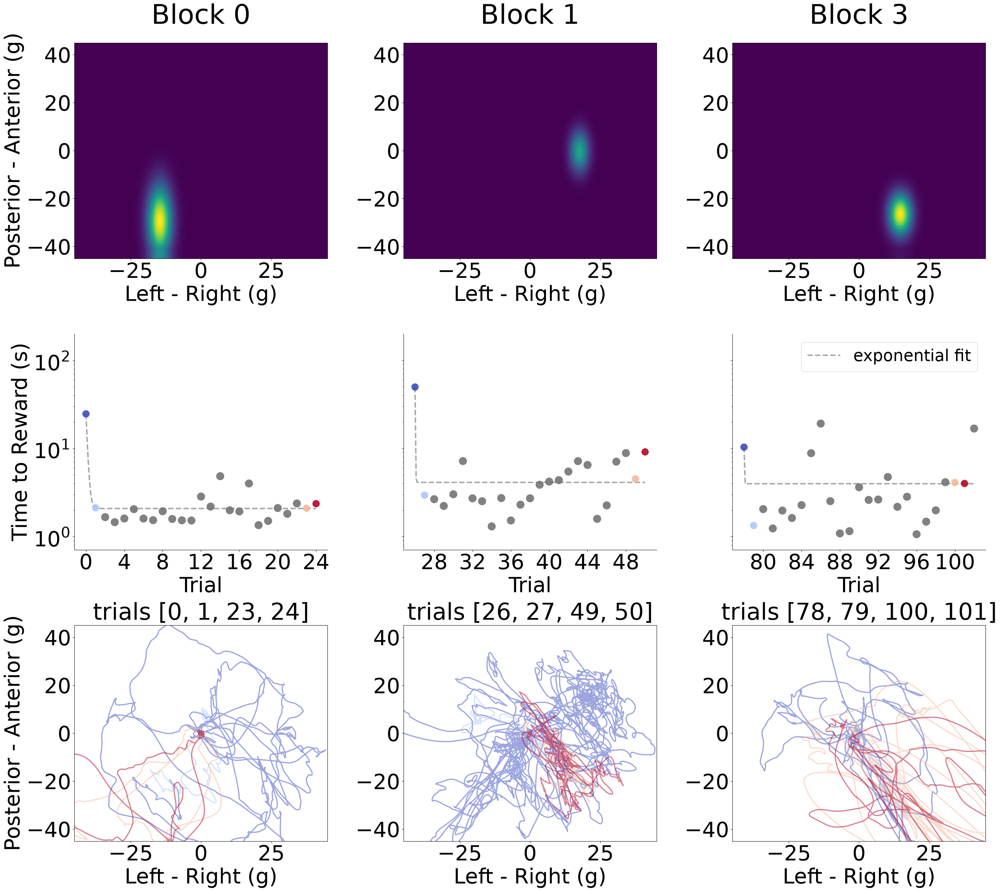

In [29]:
FONT_LABEL = 44
FONT_TITLE = 56
FONT_TRIAL_TITLE = 48
FONT_LEGEND = 34

fig = plt.figure(figsize=(34, 30))
gs = plt.GridSpec(3, 3, figure=fig, width_ratios=[1, 1, 1],
                   height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)

# --- row 0: target area ---
lut_data_h11 = []
for label, block in block_groups_h11:
    key = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id_h11, session_h11, task_setting_id)
    lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    lut_data_h11.append((label, lut, lut_extent))
lut_vmin = min(np.min(l) for _, l, _ in lut_data_h11)
lut_vmax = max(np.max(l) for _, l, _ in lut_data_h11)

im_target = None
axes_target = []
for col, (label, lut, lut_extent) in enumerate(lut_data_h11):
    ax = fig.add_subplot(gs[0, col])
    lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_force_range_h11)
    im_target = ax.imshow(lut_disp, extent=uniform_force_range_h11, origin='lower', cmap='viridis',
                           aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
    ax.set_xlim(uniform_force_range_h11[:2])
    ax.set_ylim(uniform_force_range_h11[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
    ax.tick_params(labelsize=FONT_LABEL)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
    axes_target.append(ax)

for ax, (label, _) in zip(axes_target, block_groups_h11):
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.012, label, ha='center', va='bottom', fontsize=FONT_TITLE)

# --- row 1: time to reward (log scale); only the trials used in row 2 are colored
#     early=blue -> late=red (matching row 2's coloring), the rest are neutral gray;
#     a faint dashed exponential-decay fit shows the block's overall learning trend ---
group_data_h11 = []
for label, block in block_groups_h11:
    key = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}
    trials, _, response_value = bp._fetch_quiescence_response(experiment, key)
    order = np.argsort(trials)
    group_data_h11.append((label, trials[order], response_value[order]))
all_response_h11 = np.concatenate([r for _, _, r in group_data_h11])
ymin_h11, ymax_h11 = all_response_h11.min(), all_response_h11.max()

selected_by_label_h11 = {label: trials_selected_h11[block] for label, block in block_groups_h11}

axes_reward = []
fit_handle = None
for col, (label, trials, response_value) in enumerate(group_data_h11):
    ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
    popt = fit_exponential_trend(trials, response_value)
    if popt is not None:
        x_fit = np.linspace(trials.min(), trials.max(), 200)
        y_fit = exp_decay(x_fit - trials.min(), *popt)
        fit_handle, = ax.plot(x_fit, y_fit, '--', color='black', alpha=0.35, linewidth=3, zorder=1,
                               label='exponential fit')
    sel_trials = selected_by_label_h11[label]
    n_sel = len(sel_trials)
    frac_by_trial = {t: i / max(n_sel - 1, 1) for i, t in enumerate(sel_trials)}
    is_selected = np.array([t in frac_by_trial for t in trials])
    ax.scatter(trials[~is_selected], response_value[~is_selected], color=(0.45, 0.45, 0.45, 1.0),
               s=280, alpha=0.9, edgecolor='none', zorder=2)
    selected_colors = [bp.cm.coolwarm(frac_by_trial[t]) for t in trials[is_selected]]
    ax.scatter(trials[is_selected], response_value[is_selected], c=selected_colors,
               s=230, alpha=0.9, edgecolor='none', zorder=3)
    ax.set_xlabel('Trial', fontsize=FONT_LABEL)
    ax.set_yscale('log')
    ax.set_ylim(ymin_h11 / 1.5, ymax_h11 * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=FONT_LABEL)
    if col == 0:
        ax.set_ylabel('Time to Reward (s)', fontsize=FONT_LABEL)
    else:
        plt.setp(ax.get_yticklabels(), visible=False)
    axes_reward.append(ax)
if fit_handle is not None:
    axes_reward[-1].legend(handles=[fit_handle], loc='upper right', fontsize=FONT_LEGEND, frameon=True)

# --- row 2: force trajectories, selected trials, quiescence-baselined ---
axes_traj = []
for col, (label, block) in enumerate(block_groups_h11):
    trials = trials_selected_h11[block]
    ax = fig.add_subplot(gs[2, col])
    lr_traces, pa_traces = lr_pa_traces_quiescence_baseline(subject_id_h11, session_h11, block, trials)
    n_traj = len(lr_traces)
    for i, (lr, pa) in enumerate(zip(lr_traces, pa_traces)):
        traj_color = bp.cm.coolwarm(i / max(n_traj - 1, 1))
        ax.plot(lr, pa, '-', color=traj_color, alpha=0.5, linewidth=2.5)
    ax.set_xlim(uniform_force_range_h11[:2])
    ax.set_ylim(uniform_force_range_h11[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
    ax.set_title(f'trials {trials}', fontsize=FONT_TRIAL_TITLE)
    ax.tick_params(labelsize=FONT_LABEL)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
    axes_traj.append(ax)

out_path = alt_dir / 'combined_human_11_target_reward_trajectories_poster.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Poster-scale redo: human_11 combined figure, no fitted line

Same as the poster-scale human_11 figure above, but without the exponential-decay
fit line on the "Time to Reward" panels (the fit collapsed almost immediately due
to each block's large first-trial outlier, so it wasn't a useful trend indicator
here).

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\combined_human_11_target_reward_trajectories_poster_nofit.png

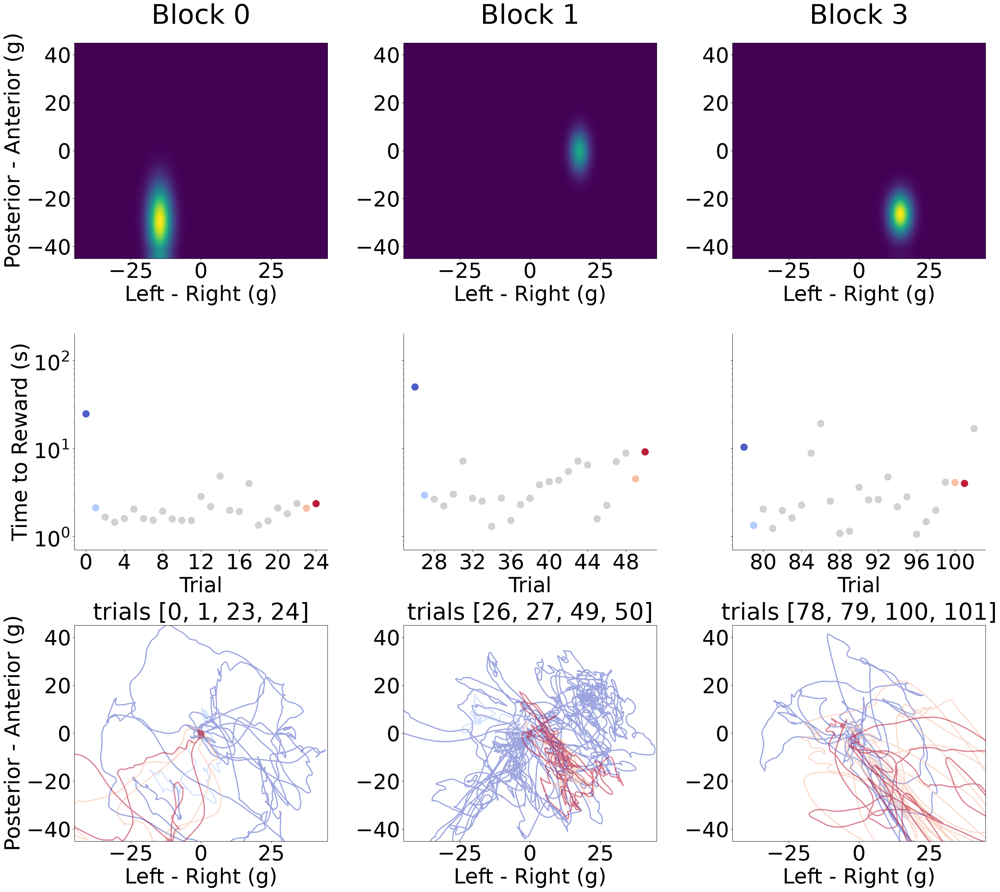

In [30]:
FONT_LABEL = 44
FONT_TITLE = 56
FONT_TRIAL_TITLE = 48

fig = plt.figure(figsize=(34, 30))
gs = plt.GridSpec(3, 3, figure=fig, width_ratios=[1, 1, 1],
                   height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)

# --- row 0: target area ---
lut_data_h11 = []
for label, block in block_groups_h11:
    key = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}
    task_setting_id, target_force_lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id_h11, session_h11, task_setting_id)
    lut, lut_extent, lr_extent, pa_extent = bp._normalize_lut(target_force_lut, force_axes_dict, lr_idx, pa_idx, lr_sign, pa_sign)
    lut_data_h11.append((label, lut, lut_extent))
lut_vmin = min(np.min(l) for _, l, _ in lut_data_h11)
lut_vmax = max(np.max(l) for _, l, _ in lut_data_h11)

im_target = None
axes_target = []
for col, (label, lut, lut_extent) in enumerate(lut_data_h11):
    ax = fig.add_subplot(gs[0, col])
    lut_disp = bp._pad_lut_to_range(lut, lut_extent, uniform_force_range_h11)
    im_target = ax.imshow(lut_disp, extent=uniform_force_range_h11, origin='lower', cmap='viridis',
                           aspect='auto', vmin=lut_vmin, vmax=lut_vmax)
    ax.set_xlim(uniform_force_range_h11[:2])
    ax.set_ylim(uniform_force_range_h11[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
    ax.tick_params(labelsize=FONT_LABEL)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
    axes_target.append(ax)

for ax, (label, _) in zip(axes_target, block_groups_h11):
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.012, label, ha='center', va='bottom', fontsize=FONT_TITLE)

# --- row 1: time to reward (log scale); only the trials used in row 2 are colored
#     early=blue -> late=red (matching row 2's coloring), the rest are neutral gray;
#     a faint dashed exponential-decay fit shows the block's overall learning trend ---
group_data_h11 = []
for label, block in block_groups_h11:
    key = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block}
    trials, _, response_value = bp._fetch_quiescence_response(experiment, key)
    order = np.argsort(trials)
    group_data_h11.append((label, trials[order], response_value[order]))
all_response_h11 = np.concatenate([r for _, _, r in group_data_h11])
ymin_h11, ymax_h11 = all_response_h11.min(), all_response_h11.max()

selected_by_label_h11 = {label: trials_selected_h11[block] for label, block in block_groups_h11}

axes_reward = []
for col, (label, trials, response_value) in enumerate(group_data_h11):
    ax = fig.add_subplot(gs[1, col], sharey=axes_reward[0] if axes_reward else None)
    sel_trials = selected_by_label_h11[label]
    n_sel = len(sel_trials)
    frac_by_trial = {t: i / max(n_sel - 1, 1) for i, t in enumerate(sel_trials)}
    dot_colors = [bp.cm.coolwarm(frac_by_trial[t]) if t in frac_by_trial else (0.8, 0.8, 0.8, 1.0)
                  for t in trials]
    ax.scatter(trials, response_value, c=dot_colors, s=230, alpha=0.9, edgecolor='none', zorder=2)
    ax.set_xlabel('Trial', fontsize=FONT_LABEL)
    ax.set_yscale('log')
    ax.set_ylim(ymin_h11 / 1.5, ymax_h11 * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=FONT_LABEL)
    if col == 0:
        ax.set_ylabel('Time to Reward (s)', fontsize=FONT_LABEL)
    else:
        plt.setp(ax.get_yticklabels(), visible=False)
    axes_reward.append(ax)

# --- row 2: force trajectories, selected trials, quiescence-baselined ---
axes_traj = []
for col, (label, block) in enumerate(block_groups_h11):
    trials = trials_selected_h11[block]
    ax = fig.add_subplot(gs[2, col])
    lr_traces, pa_traces = lr_pa_traces_quiescence_baseline(subject_id_h11, session_h11, block, trials)
    n_traj = len(lr_traces)
    for i, (lr, pa) in enumerate(zip(lr_traces, pa_traces)):
        traj_color = bp.cm.coolwarm(i / max(n_traj - 1, 1))
        ax.plot(lr, pa, '-', color=traj_color, alpha=0.5, linewidth=2.5)
    ax.set_xlim(uniform_force_range_h11[:2])
    ax.set_ylim(uniform_force_range_h11[2:])
    ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
    ax.set_title(f'trials {trials}', fontsize=FONT_TRIAL_TITLE)
    ax.tick_params(labelsize=FONT_LABEL)
    if col == 0:
        ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
    axes_traj.append(ax)

out_path = alt_dir / 'combined_human_11_target_reward_trajectories_poster_nofit.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## Trial 14 overlay, inverted lickport axis (two variants)

Both based on `trial14_lickport_vs_force_overlay_poster_black`, with the lickport
position axis inverted (so the trace visually descends as the port approaches
threshold, echoing the downward-right pull toward the target in the force-
trajectory panel) and the quiescence/response/reward background shading removed.

**Variant 1** leaves the panel otherwise blank behind the trace.
**Variant 2** replaces that shading with a continuous background colored by the
lickport's own instantaneous speed (|d(position)/dt|, gaussian-smoothed), using the
same viridis colormap as the target-area heatmap - fast segments render yellow/green
(similar to the target's high-speed zone), slow segments render dark purple. This
isn't the same physical quantity as the target LUT's reward-port speed (different
units), but reusing the same colormap creates the intended visual echo: "the
background gets bright exactly where the trace is moving fast," inviting the same
reading as the yellow target region.


Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial14_lickport_vs_force_overlay_poster_black_inverted.png

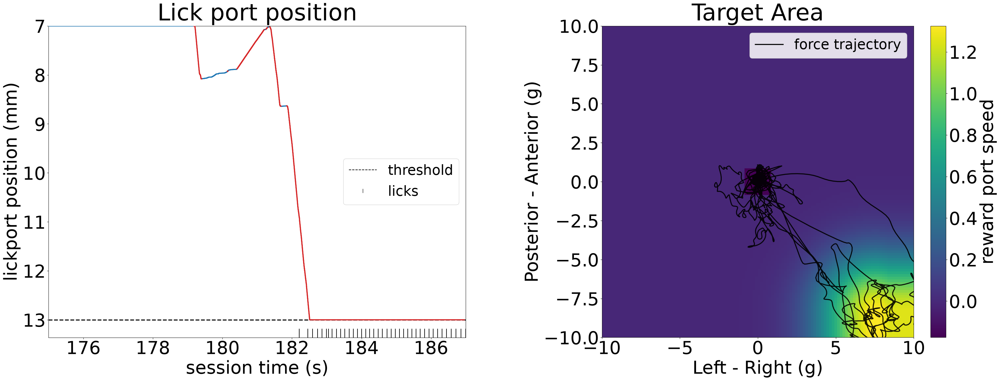

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\trial14_lickport_vs_force_overlay_poster_black_inverted_speedbg.png

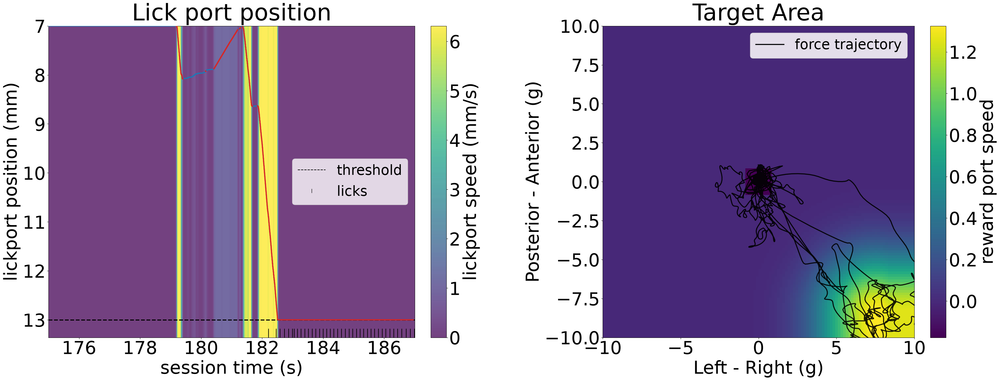

In [31]:
def lickport_speed(t, v, smooth_sigma_ms=20.0):
    """Gaussian-smoothed |velocity| of a lickport position trace."""
    sample_interval_s = np.median(np.diff(t))
    sigma_samples = bp.ms_to_samples_float(smooth_sigma_ms, sample_interval_s, minimum=1e-6)
    v_smooth = bp._filter_trace(v, 'gaussian', sigma=sigma_samples)
    velocity = np.gradient(v_smooth, t)
    return np.abs(velocity)


def lickport_speed_segmented(t, v, boundary_t, smooth_sigma_ms=20.0):
    """Same as lickport_speed, but computed separately on either side of
    boundary_t. t_lp_ext/v_lp_ext splice trial 14's own samples together with
    trial 15's quiescence samples across a real logging gap (trial 14 stops
    logging near threshold, and the port resets to a different position by the
    time trial 15's quiescence starts) - a plain gradient across that join
    produces one huge, spurious velocity spike. Splitting avoids that."""
    speed = np.zeros_like(v)
    for mask in [t < boundary_t, t >= boundary_t]:
        if mask.sum() < 3:
            continue
        speed[mask] = lickport_speed(t[mask], v[mask], smooth_sigma_ms=smooth_sigma_ms)
    return speed


speed_ext = lickport_speed_segmented(t_lp_ext, v_lp_ext, abs_t14_end)

# --- variant 1: inverted axis, no epoch background ---
fig, (ax_lp, ax_overlay) = plt.subplots(1, 2, figsize=(34, 13))

ax_lp.axhline(threshold_position, color='black', linestyle='--', linewidth=2.5, zorder=2)

v_lp_continuous = np.where(~is_step_ext, v_lp_ext, np.nan)
v_lp_step = np.where(is_step_ext, v_lp_ext, np.nan)
ax_lp.step(t_lp_ext, v_lp_continuous, where='post', color=color_continuous, linewidth=2.8, zorder=3)
ax_lp.step(t_lp_ext, v_lp_step, where='post', color=color_step, linewidth=2.8, zorder=3)

y0, y1 = v_lp_ext.min(), v_lp_ext.max()
tick_height = 0.06 * (y1 - y0)
ax_lp.eventplot(lick_abs, orientation='horizontal', lineoffsets=y1 + tick_height, linelengths=tick_height, colors='black', zorder=3)

ax_lp.set_xlim(window_start, window_end)
ax_lp.set_ylim(y0, y1 + tick_height)
ax_lp.invert_yaxis()
ax_lp.set_xlabel('session time (s)', fontsize=FONT_LABEL)
ax_lp.set_ylabel('lickport position (mm)', fontsize=FONT_LABEL)
ax_lp.set_title('Lick port position', fontsize=FONT_TITLE)
ax_lp.tick_params(labelsize=FONT_LABEL)
ax_lp.legend(handles=[
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=10, label='licks'),
], loc='center right', fontsize=FONT_LEGEND)

im_target = ax_overlay.imshow(lut_disp_ov, extent=trial_uniform_range, origin='lower', cmap='viridis', aspect='equal')
ax_overlay.plot(lr_smooth, pa_smooth, '-', color='black', linewidth=TRAJECTORY_LINEWIDTH, alpha=0.9)
ax_overlay.set_xlim(trial_uniform_range[:2])
ax_overlay.set_ylim(trial_uniform_range[2:])
ax_overlay.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
ax_overlay.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
ax_overlay.set_title('Target Area', fontsize=FONT_TITLE)
ax_overlay.tick_params(labelsize=FONT_LABEL)
ax_overlay.legend(handles=[
    Line2D([0], [0], color='black', linewidth=TRAJECTORY_LINEWIDTH, label='force trajectory'),
], loc='upper right', fontsize=FONT_LEGEND, facecolor='white', framealpha=0.85)
cbar = fig.colorbar(im_target, ax=ax_overlay, fraction=0.046, pad=0.04)
cbar.set_label('reward port speed', fontsize=FONT_LABEL)
cbar.ax.tick_params(labelsize=FONT_LABEL)

plt.tight_layout(w_pad=4.0)
out_path = alt_dir / 'trial14_lickport_vs_force_overlay_poster_black_inverted.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

# --- variant 2: inverted axis, background colored by lickport speed (viridis) ---
fig, (ax_lp, ax_overlay) = plt.subplots(1, 2, figsize=(34, 13))

y0, y1 = v_lp_ext.min(), v_lp_ext.max()
tick_height = 0.06 * (y1 - y0)
y_bg_top = y1 + tick_height

# normalize/crop to the visible window only, so the color scale reflects what's
# actually shown rather than being washed out by the much larger full-trace range
# imshow implicitly assumes its array columns are evenly spaced across the
# extent, but t_lp_ext is very unevenly sampled (dense during the trial, then a
# multi-second real gap before trial 15's quiescence) - resample onto a uniform
# time grid first so the displayed background is actually aligned with time
t_uniform = np.linspace(window_start, window_end, 3000)
speed_uniform = np.interp(t_uniform, t_lp_ext, speed_ext)
speed_vmax = np.percentile(speed_uniform, 95)

speed_arr = speed_uniform[np.newaxis, :]
im_bg = ax_lp.imshow(speed_arr, aspect='auto', extent=[window_start, window_end, y0, y_bg_top],
                      cmap='viridis', origin='lower', vmin=0, vmax=speed_vmax, alpha=0.75, zorder=0)

ax_lp.axhline(threshold_position, color='black', linestyle='--', linewidth=2.5, zorder=2)

v_lp_continuous = np.where(~is_step_ext, v_lp_ext, np.nan)
v_lp_step = np.where(is_step_ext, v_lp_ext, np.nan)
ax_lp.step(t_lp_ext, v_lp_continuous, where='post', color=color_continuous, linewidth=2.8, zorder=3)
ax_lp.step(t_lp_ext, v_lp_step, where='post', color=color_step, linewidth=2.8, zorder=3)

ax_lp.eventplot(lick_abs, orientation='horizontal', lineoffsets=y1 + tick_height, linelengths=tick_height, colors='black', zorder=3)

ax_lp.set_xlim(window_start, window_end)
ax_lp.set_ylim(y0, y_bg_top)
ax_lp.invert_yaxis()
ax_lp.set_xlabel('session time (s)', fontsize=FONT_LABEL)
ax_lp.set_ylabel('lickport position (mm)', fontsize=FONT_LABEL)
ax_lp.set_title('Lick port position', fontsize=FONT_TITLE)
ax_lp.tick_params(labelsize=FONT_LABEL)
ax_lp.legend(handles=[
    Line2D([0], [0], color='black', linestyle='--', label='threshold'),
    Line2D([0], [0], color='black', marker='|', linestyle='None', markersize=10, label='licks'),
], loc='center right', fontsize=FONT_LEGEND)
cbar_bg = fig.colorbar(im_bg, ax=ax_lp, fraction=0.046, pad=0.04)
cbar_bg.set_label('lickport speed (mm/s)', fontsize=FONT_LABEL)
cbar_bg.ax.tick_params(labelsize=FONT_LABEL)

im_target = ax_overlay.imshow(lut_disp_ov, extent=trial_uniform_range, origin='lower', cmap='viridis', aspect='equal')
ax_overlay.plot(lr_smooth, pa_smooth, '-', color='black', linewidth=TRAJECTORY_LINEWIDTH, alpha=0.9)
ax_overlay.set_xlim(trial_uniform_range[:2])
ax_overlay.set_ylim(trial_uniform_range[2:])
ax_overlay.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
ax_overlay.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
ax_overlay.set_title('Target Area', fontsize=FONT_TITLE)
ax_overlay.tick_params(labelsize=FONT_LABEL)
ax_overlay.legend(handles=[
    Line2D([0], [0], color='black', linewidth=TRAJECTORY_LINEWIDTH, label='force trajectory'),
], loc='upper right', fontsize=FONT_LEGEND, facecolor='white', framealpha=0.85)
cbar = fig.colorbar(im_target, ax=ax_overlay, fraction=0.046, pad=0.04)
cbar.set_label('reward port speed', fontsize=FONT_LABEL)
cbar.ax.tick_params(labelsize=FONT_LABEL)

plt.tight_layout(w_pad=4.0)
out_path = alt_dir / 'trial14_lickport_vs_force_overlay_poster_black_inverted_speedbg.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## New subject: M028, day 27 (2026-09-08), block 1 - target area

A single target-area heatmap (reward port speed as a function of the applied
Left-Right / Posterior-Anterior force vector) for a new subject, M028, session 27,
block 1.

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\M028_s27_b1_target_area.png

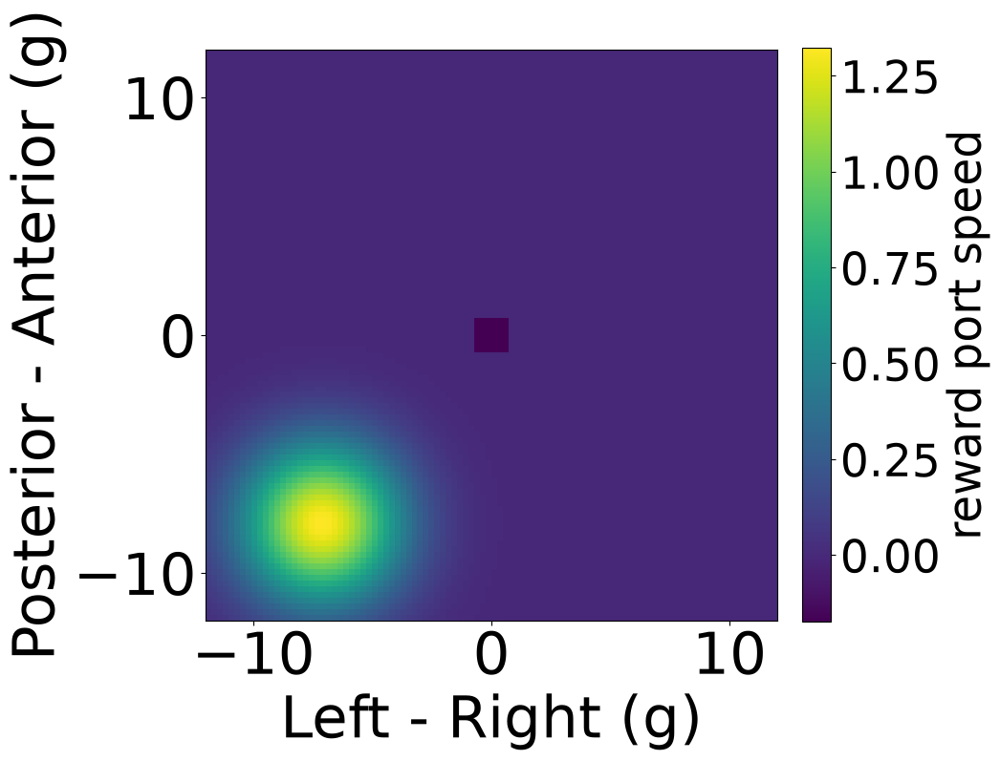

In [32]:
FONT_LABEL = 44
FONT_LEGEND = 34

subject_id_m028 = 'M028'
session_m028 = 27
block_m028 = 1
uniform_force_range_m028 = np.array([-1, 1, -1, 1]) * 12  # g

key_m028 = {'subject_id': subject_id_m028, 'session': session_m028, 'block': block_m028}
task_setting_id_m028, target_force_lut_m028 = (experiment.TaskSettings() * experiment.Block() & key_m028).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_m028, lr_idx_m028, pa_idx_m028, lr_sign_m028, pa_sign_m028 = bp._get_block_force_axes(
    experiment, subject_id_m028, session_m028, task_setting_id_m028)
lut_m028, lut_extent_m028, _, _ = bp._normalize_lut(
    target_force_lut_m028, force_axes_dict_m028, lr_idx_m028, pa_idx_m028, lr_sign_m028, pa_sign_m028)
lut_disp_m028 = bp._pad_lut_to_range(lut_m028, lut_extent_m028, uniform_force_range_m028)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(lut_disp_m028, extent=uniform_force_range_m028, origin='lower', cmap='viridis', aspect='equal')
ax.set_xlim(uniform_force_range_m028[:2])
ax.set_ylim(uniform_force_range_m028[2:])
ax.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
ax.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
ax.tick_params(labelsize=FONT_LABEL)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('reward port speed', fontsize=FONT_LEGEND)
cbar.ax.tick_params(labelsize=FONT_LEGEND)

plt.tight_layout()
out_path = alt_dir / f'{subject_id_m028}_s{session_m028}_b{block_m028}_target_area.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()

## human_11, block 2 (not included in the combined figure)

Block 2 was left out of `combined_human_11_target_reward_trajectories_poster_nofit`
(which used blocks 0, 1, 3). This adds it as its own figure, same data/methodology
and the same styling (44pt axis labels, 56pt block header, 48pt panel title, no
exponential fit, no colorbars, quiescence-baselined force trajectories) - selected
trials are again the block's first 2 and last 2 (trials 52, 53, 75, 76).

Saved to

C:\NDNF-pipeline\Notebooks\figures\alternatives\human_11_block2_target_reward_trajectories_poster.png

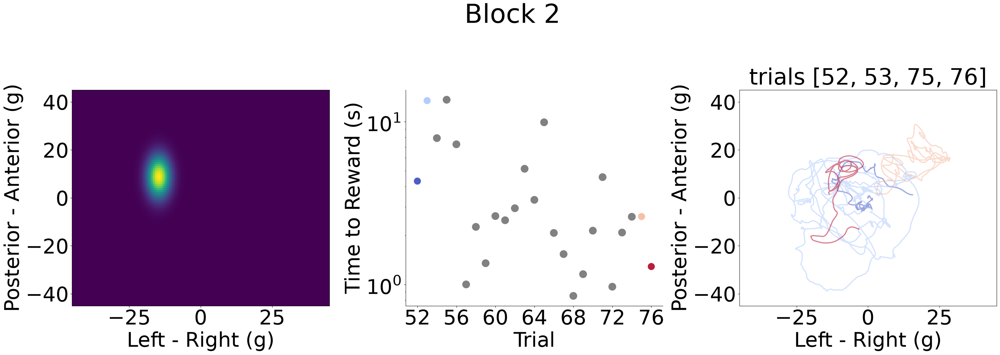

In [33]:
FONT_LABEL = 44
FONT_TITLE = 56
FONT_TRIAL_TITLE = 48

block2_h11 = 2
key_block2_h11 = {'subject_id': subject_id_h11, 'session': session_h11, 'block': block2_h11}
trials_block2_h11, _, response_block2_h11 = bp._fetch_quiescence_response(experiment, key_block2_h11)
order_b2 = np.argsort(trials_block2_h11)
trials_block2_h11, response_block2_h11 = trials_block2_h11[order_b2], response_block2_h11[order_b2]
selected_block2_h11 = sorted(trials_block2_h11[:2].tolist() + trials_block2_h11[-2:].tolist())

fig, (ax_target, ax_reward, ax_traj) = plt.subplots(1, 3, figsize=(30, 10))

# --- target area ---
task_setting_id_b2, target_force_lut_b2 = (experiment.TaskSettings() * experiment.Block() & key_block2_h11).fetch1(
    'task_setting_id', 'target_force_lut')
force_axes_dict_b2, lr_idx_b2, pa_idx_b2, lr_sign_b2, pa_sign_b2 = bp._get_block_force_axes(
    experiment, subject_id_h11, session_h11, task_setting_id_b2)
lut_b2, lut_extent_b2, _, _ = bp._normalize_lut(
    target_force_lut_b2, force_axes_dict_b2, lr_idx_b2, pa_idx_b2, lr_sign_b2, pa_sign_b2)
lut_disp_b2 = bp._pad_lut_to_range(lut_b2, lut_extent_b2, uniform_force_range_h11)

im_target = ax_target.imshow(lut_disp_b2, extent=uniform_force_range_h11, origin='lower', cmap='viridis', aspect='auto')
ax_target.set_xlim(uniform_force_range_h11[:2])
ax_target.set_ylim(uniform_force_range_h11[2:])
ax_target.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
ax_target.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
ax_target.tick_params(labelsize=FONT_LABEL)

# big header, above the middle panel, matching the block-header style
pos = ax_reward.get_position()
fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.10, 'Block 2', ha='center', va='bottom', fontsize=FONT_TITLE)

# --- time to reward (log scale); selected trials colored early=blue -> late=red ---
n_sel_b2 = len(selected_block2_h11)
frac_by_trial_b2 = {t: i / max(n_sel_b2 - 1, 1) for i, t in enumerate(selected_block2_h11)}
is_selected_b2 = np.array([t in frac_by_trial_b2 for t in trials_block2_h11])
ax_reward.scatter(trials_block2_h11[~is_selected_b2], response_block2_h11[~is_selected_b2],
                   color=(0.45, 0.45, 0.45, 1.0), s=280, alpha=0.9, edgecolor='none', zorder=2)
selected_colors_b2 = [bp.cm.coolwarm(frac_by_trial_b2[t]) for t in trials_block2_h11[is_selected_b2]]
ax_reward.scatter(trials_block2_h11[is_selected_b2], response_block2_h11[is_selected_b2],
                   c=selected_colors_b2, s=230, alpha=0.9, edgecolor='none', zorder=3)
ax_reward.set_xlabel('Trial', fontsize=FONT_LABEL)
ax_reward.set_ylabel('Time to Reward (s)', fontsize=FONT_LABEL)
ax_reward.set_yscale('log')
ax_reward.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
ax_reward.spines['top'].set_visible(False)
ax_reward.spines['right'].set_visible(False)
ax_reward.tick_params(labelsize=FONT_LABEL)

# --- force trajectories, selected trials, quiescence-baselined ---
lr_traces_b2, pa_traces_b2 = lr_pa_traces_quiescence_baseline(subject_id_h11, session_h11, block2_h11, selected_block2_h11)
n_traj_b2 = len(lr_traces_b2)
for i, (lr, pa) in enumerate(zip(lr_traces_b2, pa_traces_b2)):
    traj_color = bp.cm.coolwarm(i / max(n_traj_b2 - 1, 1))
    ax_traj.plot(lr, pa, '-', color=traj_color, alpha=0.5, linewidth=2.5)
ax_traj.set_xlim(uniform_force_range_h11[:2])
ax_traj.set_ylim(uniform_force_range_h11[2:])
ax_traj.set_xlabel('Left - Right (g)', fontsize=FONT_LABEL)
ax_traj.set_ylabel('Posterior - Anterior (g)', fontsize=FONT_LABEL)
ax_traj.set_title(f'trials {selected_block2_h11}', fontsize=FONT_TRIAL_TITLE)
ax_traj.tick_params(labelsize=FONT_LABEL)

plt.tight_layout(rect=[0, 0, 1, 0.88])
out_path = alt_dir / 'human_11_block2_target_reward_trajectories_poster.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
print('Saved to', out_path)
plt.show()